
# Preparação dos Dados para Modelagem Supervisionada

## 1. Objetivo

Esta etapa tem como objetivo preparar a base analítica de alfabetização para o desenvolvimento de modelos supervisionados de classificação binária.

A variável-alvo é `alfabetizado`, que indica se o aluno foi considerado alfabetizado (1) ou não alfabetizado (0).

## 2. Base de dados

A modelagem utilizará a camada Gold desenvolvida a partir da pipeline de engenharia de dados, contendo registros individuais de alunos avaliados em 2023 e 2024, enriquecidos com indicadores territoriais, populacionais e educacionais.

## 3. Etapas previstas

- Auditar as variáveis disponíveis e seus valores ausentes.
- Selecionar as variáveis explicativas.
- Identificar e prevenir vazamento de informação (*data leakage*).
- Definir os conjuntos de treinamento, validação e teste.
- Construir uma pipeline reproduzível de pré-processamento.
- Preparar os dados para treinamento e avaliação dos modelos.

## 4. Cuidados metodológicos

A seleção das variáveis deverá considerar sua disponibilidade no momento da previsão.

Identificadores e informações diretamente derivadas do resultado da avaliação não serão utilizados como atributos preditivos.

A estratégia de validação deverá considerar as diferenças entre os anos e o compartilhamento de características municipais entre alunos.

In [1]:

from pathlib import Path
import pandas as pd

# localizando a base analítica da camada Gold
caminho = Path("data/gold/base_analitica_alfabetizacao.parquet")

if not caminho.exists():
    caminho = Path("../data/gold/base_analitica_alfabetizacao.parquet")

# selecionando as colunas necessárias para a auditoria
colunas = [
    "ano",
    "id_municipio",
    "rede_codigo",
    "serie_codigo",
    "alfabetizado",
    "populacao_residente",
    "area_km2",
    "densidade_demografica",
    "escolas_publicas_anos_iniciais",
    "matriculas_publicas_anos_iniciais",
    "pct_escolas_com_biblioteca",
    "pct_escolas_com_internet_alunos",
    "pct_escolas_com_internet_aprendizagem",
    "pct_escolas_com_laboratorio_informatica",
    "pct_escolas_municipais",
]

# carregando somente as colunas selecionadas
df_modelo = pd.read_parquet(caminho, columns=colunas)

# conferindo as dimensões
print("Dimensão da base:", df_modelo.shape)

# verificando os tipos das variáveis
print("\nTipos de dados:")
print(df_modelo.dtypes.to_string())

# identificando valores ausentes
print("\nValores ausentes:")
print(df_modelo.isna().sum().to_string())

# verificando a distribuição por ano e rede
print("\nAlunos por ano e rede:")
print(
    df_modelo.groupby(["ano", "rede_codigo"])
    .size()
    .to_string()
)

# identificando as séries presentes
print("\nDistribuição por série:")
print(
    df_modelo["serie_codigo"]
    .value_counts(dropna=False)
    .to_string()
)


Dimensão da base: (3354661, 15)

Tipos de dados:
ano                                                 int64
id_municipio                               string[python]
rede_codigo                                string[python]
serie_codigo                               string[python]
alfabetizado                                        int64
populacao_residente                                 int64
area_km2                                          float64
densidade_demografica                             float64
escolas_publicas_anos_iniciais                      int64
matriculas_publicas_anos_iniciais                   Int64
pct_escolas_com_biblioteca                        Float64
pct_escolas_com_internet_alunos                   Float64
pct_escolas_com_internet_aprendizagem             Float64
pct_escolas_com_laboratorio_informatica           Float64
pct_escolas_municipais                            float64

Valores ausentes:
ano                                        0
id_municipio     


## 5. Auditoria da granularidade das variáveis

A base contém registros individuais de alunos, mas a maior parte das variáveis explicativas está disponível no nível municipal.

Nesta etapa, será investigada a quantidade de alunos que compartilham o mesmo contexto de município, ano e rede de ensino.

Essa verificação é importante para compreender as limitações preditivas da base e orientar a estratégia de separação entre treinamento, validação e teste, evitando avaliações excessivamente otimistas.


In [2]:

# agrupando alunos que compartilham o mesmo contexto
grupos_contexto = (
    df_modelo.groupby(
        ["ano", "id_municipio", "rede_codigo"]
    )
    .agg(
        quantidade_alunos=("alfabetizado", "size"),
        taxa_alfabetizacao=("alfabetizado", "mean"),
        classes_presentes=("alfabetizado", "nunique"),
    )
    .reset_index()
)

# verificando a quantidade de grupos
print("Total de grupos município-ano-rede:", len(grupos_contexto))

# analisando quantos alunos compartilham cada contexto
print("\nDistribuição de alunos por grupo:")
print(
    grupos_contexto["quantidade_alunos"]
    .describe()
    .round(2)
)

# identificando grupos com alunos alfabetizados e não alfabetizados
grupos_duas_classes = (
    grupos_contexto["classes_presentes"] == 2
).sum()

print("\nGrupos com alunos das duas classes:", grupos_duas_classes)

print("\nPercentual de grupos com duas classes:")
print(
    round(grupos_duas_classes / len(grupos_contexto) * 100, 2)
)

# verificando os maiores grupos
print("\nCinco maiores grupos:")
print(
    grupos_contexto.nlargest(5, "quantidade_alunos")
    .to_string(index=False)
)


Total de grupos município-ano-rede: 12417

Distribuição de alunos por grupo:
count    12417.00
mean       270.17
std       1099.30
min          1.00
25%         42.00
50%         91.00
75%        214.00
max      52622.00
Name: quantidade_alunos, dtype: float64

Grupos com alunos das duas classes: 12242

Percentual de grupos com duas classes:
98.59

Cinco maiores grupos:
 ano id_municipio rede_codigo  quantidade_alunos  taxa_alfabetizacao  classes_presentes
2024      3550308           2              52622            0.630383                  2
2023      3304557           3              44858            0.575683                  2
2024      3304557           3              43340            0.642547                  2
2024      3550308           3              41751            0.484683                  2
2024      5300108           2              22111            0.594274                  2



## 6. Estratégia de separação dos dados

A auditoria identificou 12.417 grupos definidos por ano, município e rede de ensino. Em 98,59% desses grupos existem alunos alfabetizados e não alfabetizados.

Esse resultado evidencia uma limitação da base: diferentes alunos compartilham as mesmas características contextuais, o que restringe a capacidade de distinguir resultados individuais.

Para avaliar a generalização, será utilizada a seguinte estratégia:

- **Treinamento:** parte dos municípios com avaliações de 2023.
- **Validação:** municípios distintos dos utilizados no treinamento de 2023.
- **Teste:** avaliações de 2024, preservadas para a avaliação final.

A separação entre treinamento e validação utilizará `GroupShuffleSplit`, com agrupamento por município e semente aleatória fixa.

O conjunto de 2024 não será utilizado para ajustar hiperparâmetros ou selecionar o modelo.

A modelagem principal será restrita às redes públicas estadual e municipal. Os 24 registros da rede privada serão preservados na base original, mas não utilizados no treinamento principal, devido à baixa representatividade e à natureza pública dos indicadores escolares disponíveis.


In [3]:
from sklearn.model_selection import GroupShuffleSplit

# mantendo apenas as redes estadual e municipal
df_publico = df_modelo[
    df_modelo["rede_codigo"].isin(["2", "3"])
].copy()

# separando os dados por ano
dados_2023 = df_publico[df_publico["ano"] == 2023].copy()
dados_2024 = df_publico[df_publico["ano"] == 2024].copy()

# separando os municípios de 2023 entre treino e validação
separador = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

indices_treino, indices_validacao = next(
    separador.split(
        dados_2023,
        groups=dados_2023["id_municipio"],
    )
)

# criando os conjuntos
df_treino = dados_2023.iloc[indices_treino].copy()
df_validacao = dados_2023.iloc[indices_validacao].copy()
df_teste = dados_2024.copy()

# garantindo que treino e validação não compartilhem municípios
municipios_treino = set(df_treino["id_municipio"])
municipios_validacao = set(df_validacao["id_municipio"])

assert municipios_treino.isdisjoint(municipios_validacao)

# conferindo os conjuntos criados
for nome, dados in [
    ("Treino", df_treino),
    ("Validação", df_validacao),
    ("Teste", df_teste),
]:
    print(f"\n{nome}")
    print("Alunos:", len(dados))
    print("Municípios:", dados["id_municipio"].nunique())
    print(
        "Alfabetizados (%):",
        round(dados["alfabetizado"].mean() * 100, 2),
    )
    print("Anos:", sorted(dados["ano"].unique()))


Treino
Alunos: 1191838
Municípios: 3896
Alfabetizados (%): 58.77
Anos: [np.int64(2023)]

Validação
Alunos: 310971
Municípios: 975
Alfabetizados (%): 56.92
Anos: [np.int64(2023)]

Teste
Alunos: 1851828
Municípios: 5517
Alfabetizados (%): 59.78
Anos: [np.int64(2024)]



## 7. Seleção das variáveis explicativas e do alvo

A variável-alvo do modelo é `alfabetizado`, representando a classificação binária dos alunos avaliados.

As variáveis explicativas selecionadas inicialmente incluem características da rede de ensino, indicadores territoriais, informações populacionais e infraestrutura escolar pública.

Foram excluídas da modelagem:

- `proficiencia`: informação diretamente relacionada à definição da variável-alvo.
- `id_municipio` e identificadores individuais: utilizados para rastreabilidade ou validação, não como atributos preditivos.
- `serie_codigo`: apresenta valor constante (2) em todos os registros.
- `ano`: será utilizado para controlar a separação temporal, mas não como feature inicial.
- `renda_mediana_per_capita`: excluída da modelagem histórica devido à sua disponibilidade posterior às avaliações.

A seleção inicial poderá ser revisada após a avaliação dos modelos, desde que respeite a disponibilidade temporal das informações e a prevenção de data leakage.


In [4]:
# definindo as variáveis numéricas
features_numericas = [
    "populacao_residente",
    "area_km2",
    "densidade_demografica",
    "escolas_publicas_anos_iniciais",
    "matriculas_publicas_anos_iniciais",
    "pct_escolas_com_biblioteca",
    "pct_escolas_com_internet_alunos",
    "pct_escolas_com_internet_aprendizagem",
    "pct_escolas_com_laboratorio_informatica",
    "pct_escolas_municipais",
]

# definindo as variáveis categóricas
features_categoricas = [
    "rede_codigo",
]

# reunindo todas as features
features = features_numericas + features_categoricas

# separando as variáveis explicativas
X_treino = df_treino[features].copy()
X_validacao = df_validacao[features].copy()
X_teste = df_teste[features].copy()

# separando a variável-alvo
y_treino = df_treino["alfabetizado"].copy()
y_validacao = df_validacao["alfabetizado"].copy()
y_teste = df_teste["alfabetizado"].copy()

# verificando as dimensões
print("X treino:", X_treino.shape)
print("y treino:", y_treino.shape)

print("\nX validação:", X_validacao.shape)
print("y validação:", y_validacao.shape)

print("\nX teste:", X_teste.shape)
print("y teste:", y_teste.shape)

print("\nFeatures selecionadas:")
print(features)

X treino: (1191838, 11)
y treino: (1191838,)

X validação: (310971, 11)
y validação: (310971,)

X teste: (1851828, 11)
y teste: (1851828,)

Features selecionadas:
['populacao_residente', 'area_km2', 'densidade_demografica', 'escolas_publicas_anos_iniciais', 'matriculas_publicas_anos_iniciais', 'pct_escolas_com_biblioteca', 'pct_escolas_com_internet_alunos', 'pct_escolas_com_internet_aprendizagem', 'pct_escolas_com_laboratorio_informatica', 'pct_escolas_municipais', 'rede_codigo']



## 8. Pipeline de pré-processamento

O pré-processamento será realizado com `Pipeline` e `ColumnTransformer` do Scikit-learn.

As variáveis numéricas receberão imputação pela mediana e padronização com `StandardScaler`.

A variável categórica `rede_codigo` receberá imputação pela categoria mais frequente e codificação com `OneHotEncoder`.

Essas transformações serão posteriormente integradas ao modelo supervisionado.

Para evitar data leakage, os parâmetros do pré-processamento serão aprendidos exclusivamente a partir dos dados de treinamento. Os conjuntos de validação e teste receberão apenas as transformações aprendidas, sem reajuste.


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# preparando as variáveis numéricas
pipeline_numerica = Pipeline(
    steps=[
        ("imputacao", SimpleImputer(strategy="median")),
        ("padronizacao", StandardScaler()),
    ]
)

# preparando as variáveis categóricas
pipeline_categorica = Pipeline(
    steps=[
        ("imputacao", SimpleImputer(strategy="most_frequent")),
        ("codificacao", OneHotEncoder(handle_unknown="ignore")),
    ]
)

# combinando os dois tipos de processamento
preprocessador = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerica, features_numericas),
        ("categoricas", pipeline_categorica, features_categoricas),
    ]
)

# verificando a estrutura criada
print(preprocessador)

ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputacao',
                                                  SimpleImputer(strategy='median')),
                                                 ('padronizacao',
                                                  StandardScaler())]),
                                 ['populacao_residente', 'area_km2',
                                  'densidade_demografica',
                                  'escolas_publicas_anos_iniciais',
                                  'matriculas_publicas_anos_iniciais',
                                  'pct_escolas_com_biblioteca',
                                  'pct_escolas_com_internet_alunos',
                                  'pct_escolas_com_internet_aprendizagem',
                                  'pct_escolas_com_laboratorio_informatica',
                                  'pct_escolas_municipais']),
                                ('categoricas',
       

## 9. Modelo baseline

Antes do treinamento de modelos supervisionados mais complexos, será estabelecido um baseline utilizando `DummyClassifier`.

O objetivo é criar uma referência inicial de desempenho para avaliar se os próximos algoritmos realmente conseguem identificar padrões relevantes nos dados.

O baseline utilizará a estratégia `most_frequent`, prevendo sempre a classe predominante no conjunto de treinamento.

O pré-processamento será integrado ao classificador utilizando `Pipeline`, garantindo que as transformações sejam ajustadas exclusivamente com os dados de treino.

A avaliação inicial será realizada no conjunto de validação de 2023, preservando os dados de teste de 2024 para a avaliação final.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# criando uma pipeline completa com pré-processamento e modelo
modelo_baseline = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("modelo", DummyClassifier(strategy="most_frequent")),
    ]
)

# ajustando a pipeline apenas com os dados de treinamento
modelo_baseline.fit(X_treino, y_treino)

# gerando previsões para o conjunto de validação
previsoes_baseline = modelo_baseline.predict(X_validacao)

# avaliando a acurácia
acuracia = accuracy_score(y_validacao, previsoes_baseline)

print(f"Acurácia do baseline: {acuracia:.4f}")

# avaliando o desempenho por classe
print("\nRelatório de classificação:")
print(
    classification_report(
        y_validacao,
        previsoes_baseline,
        labels=[0, 1],
        target_names=["Não alfabetizado", "Alfabetizado"],
        zero_division=0,
    )
)

# verificando os acertos e erros
print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_validacao,
        previsoes_baseline,
        labels=[0, 1],
    )
)

Acurácia do baseline: 0.5692

Relatório de classificação:
                  precision    recall  f1-score   support

Não alfabetizado       0.00      0.00      0.00    133969
    Alfabetizado       0.57      1.00      0.73    177002

        accuracy                           0.57    310971
       macro avg       0.28      0.50      0.36    310971
    weighted avg       0.32      0.57      0.41    310971


Matriz de confusão:
[[     0 133969]
 [     0 177002]]


### 9.1. Resultados do baseline

O modelo baseline, utilizando `DummyClassifier` com a estratégia `most_frequent`, apresentou acurácia de 56,92% no conjunto de validação.

Entretanto, todas as previsões foram atribuídas à classe 1 (alfabetizado).

Consequentemente, o modelo apresentou recall e F1-score iguais a zero para a classe 0 (não alfabetizado), deixando de identificar os 133.969 alunos não alfabetizados presentes na validação.

Esse resultado demonstra que a acurácia isolada é insuficiente para avaliar o desempenho neste problema.

Os próximos modelos serão comparados ao baseline considerando especialmente a capacidade de identificar alunos não alfabetizados, sem desconsiderar a precisão das previsões.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# criando a pipeline completa de regressão logística
modelo_logistico = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        (
            "modelo",
            LogisticRegression(
                max_iter=500,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

# treinando somente com os dados de 2023 destinados ao treino
modelo_logistico.fit(X_treino, y_treino)

# realizando previsões nos municípios de validação
previsoes_logistico = modelo_logistico.predict(X_validacao)

# calculando a acurácia
acuracia_logistico = accuracy_score(
    y_validacao,
    previsoes_logistico,
)

print(f"Acurácia da Regressão Logística: {acuracia_logistico:.4f}")

# avaliando precision, recall e F1-score
print("\nRelatório de classificação:")
print(
    classification_report(
        y_validacao,
        previsoes_logistico,
        labels=[0, 1],
        target_names=["Não alfabetizado", "Alfabetizado"],
        zero_division=0,
    )
)

# verificando os acertos e erros por classe
print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_validacao,
        previsoes_logistico,
        labels=[0, 1],
    )
)

Acurácia da Regressão Logística: 0.5268

Relatório de classificação:
                  precision    recall  f1-score   support

Não alfabetizado       0.46      0.61      0.52    133969
    Alfabetizado       0.61      0.47      0.53    177002

        accuracy                           0.53    310971
       macro avg       0.54      0.54      0.53    310971
    weighted avg       0.55      0.53      0.53    310971


Matriz de confusão:
[[81154 52815]
 [94327 82675]]


### 9.2. Regressão Logística — Avaliação inicial

O primeiro modelo supervisionado foi desenvolvido com Regressão Logística, utilizando pré-processamento integrado à pipeline Scikit-learn e pesos balanceados entre as classes.

Na validação de 2023, o modelo apresentou:

- Acurácia: 52,68%.
- Recall da classe não alfabetizado: 0,61.
- F1-score da classe não alfabetizado: 0,52.
- F1-score macro: 0,53.

Em comparação ao DummyClassifier, a Regressão Logística apresentou menor acurácia, mas maior capacidade de identificar alunos não alfabetizados.

Entretanto, foram observados 94.327 falsos alertas e 52.815 alunos não alfabetizados não identificados.

Os resultados indicam que o modelo ainda não apresenta desempenho adequado para utilização operacional. Serão necessárias análises adicionais de discriminação, ajustes de parâmetros e comparação com outros algoritmos.

A avaliação permanece restrita ao conjunto de validação, preservando os dados de 2024 para o teste final.

In [8]:
from sklearn.metrics import roc_auc_score, average_precision_score

# obtendo a posição da classe 0 nas probabilidades
classes = modelo_logistico.named_steps["modelo"].classes_
indice_classe_0 = list(classes).index(0)

# calculando a probabilidade de não alfabetização
prob_nao_alfabetizado = modelo_logistico.predict_proba(
    X_validacao
)[:, indice_classe_0]

# transformando a classe 0 na classe positiva da avaliação
y_risco = (y_validacao == 0).astype(int)

# calculando as métricas
roc_auc = roc_auc_score(
    y_risco,
    prob_nao_alfabetizado
)

average_precision = average_precision_score(
    y_risco,
    prob_nao_alfabetizado
)

# calculando a frequência da classe de interesse
prevalencia = y_risco.mean()

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision: {average_precision:.4f}")
print(f"Proporção de não alfabetizados: {prevalencia:.4f}")

ROC-AUC: 0.5484
Average Precision: 0.4628
Proporção de não alfabetizados: 0.4308



### 9.3. Avaliação da capacidade de discriminação

A Regressão Logística apresentou ROC-AUC de 0,5484 e Average Precision de 0,4628 na validação de 2023.

A prevalência de alunos não alfabetizados no conjunto de validação foi de 0,4308, utilizada como referência para a Average Precision.

Os resultados demonstram capacidade discriminativa limitada, próxima à referência de um classificador sem discriminação.

Uma possível explicação é a baixa granularidade das variáveis explicativas, majoritariamente municipais. Dessa forma, diferentes alunos podem compartilhar as mesmas características preditivas, embora apresentem resultados distintos de alfabetização.

Será avaliado um algoritmo não linear para investigar se relações e interações mais complexas entre as variáveis permitem melhorar o desempenho.

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)

# criando uma pipeline com um modelo não linear
modelo_hgb = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        (
            "modelo",
            HistGradientBoostingClassifier(
                max_iter=100,
                max_leaf_nodes=15,
                learning_rate=0.1,
                l2_regularization=1.0,
                early_stopping=False,
                random_state=42,
            ),
        ),
    ]
)

# treinando com os dados de 2023
modelo_hgb.fit(X_treino, y_treino)

# gerando as previsões da validação
previsoes_hgb = modelo_hgb.predict(X_validacao)

# identificando a posição da classe não alfabetizado
classes_hgb = modelo_hgb.named_steps["modelo"].classes_
indice_classe_0 = list(classes_hgb).index(0)

# obtendo as probabilidades de não alfabetização
prob_hgb_0 = modelo_hgb.predict_proba(
    X_validacao
)[:, indice_classe_0]

# definindo a classe de interesse para as métricas
y_risco = (y_validacao == 0).astype(int)

# calculando as métricas
print(
    "Acurácia:",
    round(accuracy_score(y_validacao, previsoes_hgb), 4),
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_risco, prob_hgb_0), 4),
)

print(
    "Average Precision:",
    round(average_precision_score(y_risco, prob_hgb_0), 4),
)

print("\nRelatório de classificação:")
print(
    classification_report(
        y_validacao,
        previsoes_hgb,
        labels=[0, 1],
        target_names=["Não alfabetizado", "Alfabetizado"],
        zero_division=0,
    )
)

print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_validacao,
        previsoes_hgb,
        labels=[0, 1],
    )
)

Acurácia: 0.5632
ROC-AUC: 0.5654
Average Precision: 0.4769

Relatório de classificação:
                  precision    recall  f1-score   support

Não alfabetizado       0.48      0.21      0.30    133969
    Alfabetizado       0.58      0.83      0.68    177002

        accuracy                           0.56    310971
       macro avg       0.53      0.52      0.49    310971
    weighted avg       0.54      0.56      0.52    310971


Matriz de confusão:
[[ 28546 105423]
 [ 30421 146581]]



### 9.4. Comparação de algoritmos e análise de limiares

O HistGradientBoosting apresentou ROC-AUC de 0,5654 e Average Precision de 0,4769, superando ligeiramente a Regressão Logística nessas métricas.

Entretanto, utilizando o limiar padrão de classificação, seu recall para alunos não alfabetizados foi de apenas 0,21.

Como o objetivo educacional envolve identificar situações de risco, será investigado o efeito de diferentes limiares de classificação sobre precision, recall e F1-score da classe não alfabetizado.

Essa análise será realizada exclusivamente no conjunto de validação de 2023, preservando o teste temporal de 2024 para a avaliação final.

In [10]:
import numpy as np

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
)

# definindo os limiares que serão avaliados
limiares = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

resultados_limiares = []

for limiar in limiares:

    # classificando como não alfabetizado quando o risco
    # estimado for maior ou igual ao limiar
    previsoes = np.where(
        prob_hgb_0 >= limiar,
        0,
        1,
    )

    # calculando métricas para a classe não alfabetizado
    precision = precision_score(
        y_validacao,
        previsoes,
        pos_label=0,
        zero_division=0,
    )

    recall = recall_score(
        y_validacao,
        previsoes,
        pos_label=0,
        zero_division=0,
    )

    f1 = f1_score(
        y_validacao,
        previsoes,
        pos_label=0,
        zero_division=0,
    )

    # contando alunos alfabetizados sinalizados incorretamente
    falsos_alertas = (
        (y_validacao == 1) & (previsoes == 0)
    ).sum()

    resultados_limiares.append({
        "limiar": limiar,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "falsos_alertas": falsos_alertas,
    })

# organizando os resultados
comparacao_limiares = pd.DataFrame(resultados_limiares)

print(
    comparacao_limiares
    .round(4)
    .to_string(index=False)
)

 limiar  precision  recall     f1  falsos_alertas
   0.20     0.4308  1.0000 0.6022          177002
   0.25     0.4317  0.9936 0.6019          175235
   0.30     0.4419  0.9549 0.6042          161546
   0.35     0.4532  0.8815 0.5987          142455
   0.40     0.4701  0.7535 0.5790          113797
   0.45     0.4723  0.5726 0.5176           85706
   0.50     0.4841  0.2131 0.2959           30421
   0.55     0.4873  0.1388 0.2161           19564
   0.60     0.6047  0.0200 0.0387            1752


### 9.5. Conclusões da análise de limiares

A redução do limiar de classificação aumentou o recall da classe não alfabetizado, mas também elevou a quantidade de falsos alertas.

O maior F1-score entre os limiares testados foi de 0,6042, no limiar de 0,30. Entretanto, esse resultado foi muito próximo ao F1-score de uma estratégia que classifica todos os alunos como não alfabetizados.

Portanto, não foi possível identificar, apenas com o F1-score, um limiar claramente adequado para utilização operacional.

A próxima análise avaliará a capacidade dos modelos de priorizar os alunos com maiores probabilidades estimadas de não alfabetização, considerando uma capacidade limitada de atendimento.

In [11]:
import numpy as np
import pandas as pd

# definindo a proporção de alunos que poderiam receber atenção prioritária
fracao_priorizada = 0.10

# criando a referência real de alunos não alfabetizados
y_risco = (y_validacao == 0).astype(int).to_numpy()

# proporção geral de alunos não alfabetizados na validação
prevalencia = y_risco.mean()

# função para avaliar a priorização de alunos
def avaliar_priorizacao(nome_modelo, probabilidades):

    # encontrando o valor que separa os maiores riscos estimados
    limite = np.quantile(
        probabilidades,
        1 - fracao_priorizada,
    )

    # selecionando todos os alunos com risco acima ou igual ao limite
    priorizados = probabilidades >= limite

    # verificando quantos alunos foram selecionados
    quantidade = priorizados.sum()

    # calculando a proporção de não alfabetizados no grupo priorizado
    precision_topo = y_risco[priorizados].mean()

    # calculando a proporção de não alfabetizados identificados
    recall_topo = (
        y_risco[priorizados].sum() / y_risco.sum()
    )

    # comparando a precisão com a prevalência geral
    lift = precision_topo / prevalencia

    return {
        "modelo": nome_modelo,
        "alunos_priorizados": quantidade,
        "percentual_priorizado": quantidade / len(y_risco) * 100,
        "precision_topo": precision_topo,
        "recall_topo": recall_topo,
        "lift": lift,
    }


# comparando os modelos na mesma base de validação
resultados_priorizacao = pd.DataFrame([
    avaliar_priorizacao(
        "Regressão Logística",
        prob_nao_alfabetizado,
    ),
    avaliar_priorizacao(
        "HistGradientBoosting",
        prob_hgb_0,
    ),
])

print("Prevalência de não alfabetizados:", round(prevalencia, 4))

print("\nResultados da priorização:")
print(
    resultados_priorizacao
    .round(4)
    .to_string(index=False)
)

Prevalência de não alfabetizados: 0.4308

Resultados da priorização:
              modelo  alunos_priorizados  percentual_priorizado  precision_topo  recall_topo   lift
 Regressão Logística               31197                10.0321          0.4802       0.1118 1.1147
HistGradientBoosting               31224                10.0408          0.4858       0.1132 1.1277


### 9.6. Avaliação da priorização por risco

Foi realizada uma análise de priorização considerando aproximadamente 10% dos alunos com maiores probabilidades estimadas de não alfabetização.

A Regressão Logística apresentou precisão de 48,02% no grupo priorizado, com Lift de 1,1147.

O HistGradientBoosting apresentou precisão de 48,58%, com Lift de 1,1277.

A prevalência geral de alunos não alfabetizados na validação foi de 43,08%.

Embora o HistGradientBoosting tenha apresentado resultados ligeiramente superiores, a melhoria em relação à seleção aleatória foi limitada.

Os resultados sugerem que os modelos conseguem identificar algum sinal de risco educacional, mas ainda não apresentam desempenho suficiente para orientar intervenções individuais sem validações adicionais.

Uma limitação relevante é que as variáveis explicativas são predominantemente municipais, reduzindo a capacidade dos modelos de diferenciar alunos que compartilham o mesmo contexto.

A próxima etapa será investigar se a otimização dos hiperparâmetros melhora a capacidade de generalização.

In [12]:
from sklearn.base import clone

# definindo duas configurações alternativas
configuracoes = [
    {
        "nome": "Modelo mais simples",
        "max_iter": 150,
        "max_leaf_nodes": 7,
        "learning_rate": 0.05,
        "min_samples_leaf": 100,
        "l2_regularization": 5.0,
    },
    {
        "nome": "Modelo mais complexo",
        "max_iter": 200,
        "max_leaf_nodes": 31,
        "learning_rate": 0.05,
        "min_samples_leaf": 200,
        "l2_regularization": 3.0,
    },
]

resultados_otimizacao = []

for config in configuracoes:

    nome = config["nome"]

    # criando o modelo com os hiperparâmetros definidos
    classificador = HistGradientBoostingClassifier(
        max_iter=config["max_iter"],
        max_leaf_nodes=config["max_leaf_nodes"],
        learning_rate=config["learning_rate"],
        min_samples_leaf=config["min_samples_leaf"],
        l2_regularization=config["l2_regularization"],
        early_stopping=False,
        random_state=42,
    )

    # integrando o pré-processamento ao classificador
    pipeline = Pipeline(
        steps=[
            ("preprocessamento", clone(preprocessador)),
            ("modelo", classificador),
        ]
    )

    # treinando somente com os dados de treino
    pipeline.fit(X_treino, y_treino)

    # obtendo o risco estimado na validação
    indice_classe_0 = list(
        pipeline.named_steps["modelo"].classes_
    ).index(0)

    probabilidades = pipeline.predict_proba(
        X_validacao
    )[:, indice_classe_0]

    # calculando as métricas
    auc = roc_auc_score(y_risco, probabilidades)
    ap = average_precision_score(y_risco, probabilidades)

    resultados_otimizacao.append({
        "modelo": nome,
        "roc_auc": auc,
        "average_precision": ap,
    })

# incluindo o modelo inicial como referência
resultados_otimizacao.insert(
    0,
    {
        "modelo": "Modelo inicial",
        "roc_auc": 0.5654,
        "average_precision": 0.4769,
    },
)

comparacao_otimizacao = pd.DataFrame(resultados_otimizacao)

print(
    comparacao_otimizacao
    .round(4)
    .to_string(index=False)
)

              modelo  roc_auc  average_precision
      Modelo inicial   0.5654             0.4769
 Modelo mais simples   0.5707             0.4799
Modelo mais complexo   0.5661             0.4810


### 9.7. Otimização inicial dos hiperparâmetros

Foram avaliadas três configurações do HistGradientBoostingClassifier, utilizando exclusivamente os dados de treinamento e validação de 2023.

O modelo inicial apresentou ROC-AUC de 0,5654 e Average Precision de 0,4769.

A configuração mais simples apresentou o maior ROC-AUC (0,5707), enquanto a configuração mais complexa apresentou a maior Average Precision (0,4810).

As melhorias observadas foram pequenas, indicando que o ajuste dos hiperparâmetros ainda não produziu ganhos expressivos de discriminação.

A configuração mais simples será considerada candidata inicial, mas sua seleção definitiva dependerá da avaliação de overfitting e da estabilidade dos resultados em diferentes divisões de validação por município.

In [13]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

# criando a configuração mais simples do HistGradientBoosting
modelo_hgb_simples = Pipeline(
    steps=[
        ("preprocessamento", clone(preprocessador)),
        (
            "modelo",
            HistGradientBoostingClassifier(
                max_iter=150,
                max_leaf_nodes=7,
                learning_rate=0.05,
                min_samples_leaf=100,
                l2_regularization=5.0,
                early_stopping=False,
                random_state=42,
            ),
        ),
    ]
)

# treinando apenas com o conjunto de treinamento
modelo_hgb_simples.fit(X_treino, y_treino)

# identificando a posição da classe não alfabetizado
indice_classe_0 = list(
    modelo_hgb_simples.named_steps["modelo"].classes_
).index(0)

# obtendo probabilidades para treino e validação
prob_treino = modelo_hgb_simples.predict_proba(
    X_treino
)[:, indice_classe_0]

prob_validacao = modelo_hgb_simples.predict_proba(
    X_validacao
)[:, indice_classe_0]

# definindo a classe de interesse: não alfabetizado
y_treino_risco = (y_treino == 0).astype(int)
y_validacao_risco = (y_validacao == 0).astype(int)

# calculando as métricas de cada conjunto
for nome, y_real, probabilidades in [
    ("Treinamento", y_treino_risco, prob_treino),
    ("Validação", y_validacao_risco, prob_validacao),
]:
    print(f"\n{nome}")

    print(
        "ROC-AUC:",
        round(roc_auc_score(y_real, probabilidades), 4),
    )

    print(
        "Average Precision:",
        round(average_precision_score(y_real, probabilidades), 4),
    )


Treinamento
ROC-AUC: 0.6269
Average Precision: 0.5278

Validação
ROC-AUC: 0.5707
Average Precision: 0.4799


### 9.8. Avaliação de overfitting e generalização

A configuração mais simples do HistGradientBoosting apresentou ROC-AUC de 0,6269 no treinamento e 0,5707 na validação.

A diferença de 0,0562 indica redução da capacidade discriminativa em municípios não utilizados no treinamento.

Esse comportamento pode estar associado ao ajuste excessivo aos dados de treinamento e às diferenças entre os contextos municipais.

Para avaliar a estabilidade do desempenho, será realizada validação cruzada com `GroupKFold`, utilizando os municípios como grupos.

A validação cruzada será restrita aos dados de 2023. O conjunto de teste de 2024 permanecerá reservado para a avaliação final.

In [14]:
import gc

# Liberando DataFrames intermediários que não serão
# mais utilizados nas próximas etapas do notebook
variaveis_descartaveis = [
    "df_modelo",
    "df_publico",
    "grupos_contexto",
    "df_treino",
    "df_validacao",
    "df_teste",
    "X_teste",
    "modelo_baseline",
    "modelo_logistico",
    "modelo_hgb",
    "pipeline",
]

for nome in variaveis_descartaveis:
    globals().pop(nome, None)

# Solicitando a coleta de objetos sem referências
gc.collect()

print("Objetos intermediários liberados.")

Objetos intermediários liberados.


In [15]:
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

# preparando os dados de 2023
X_2023 = dados_2023[features].copy()
y_2023 = dados_2023["alfabetizado"].copy()

# utilizando os municípios para definir os grupos
grupos = dados_2023["id_municipio"]

# criando a validação cruzada com 3 divisões
validador = GroupKFold(n_splits=3)

resultados_cv = []

for fold, (idx_treino, idx_validacao) in enumerate(
    validador.split(X_2023, y_2023, groups=grupos),
    start=1,
):
    # separando os dados do fold
    X_train_fold = X_2023.iloc[idx_treino]
    X_val_fold = X_2023.iloc[idx_validacao]

    y_train_fold = y_2023.iloc[idx_treino]
    y_val_fold = y_2023.iloc[idx_validacao]

    # criando uma nova cópia do modelo para cada fold
    modelo_fold = clone(modelo_hgb_simples)

    # treinando somente com os municípios do fold de treino
    modelo_fold.fit(X_train_fold, y_train_fold)

    # identificando a posição da classe 0
    indice_classe_0 = list(
        modelo_fold.named_steps["modelo"].classes_
    ).index(0)

    # obtendo as probabilidades de não alfabetização
    probabilidades = modelo_fold.predict_proba(
        X_val_fold
    )[:, indice_classe_0]

    # definindo a classe de interesse
    y_risco_fold = (y_val_fold == 0).astype(int)

    # calculando as métricas
    roc_auc = roc_auc_score(
        y_risco_fold,
        probabilidades,
    )

    ap = average_precision_score(
        y_risco_fold,
        probabilidades,
    )

    prevalencia = y_risco_fold.mean()

    resultados_cv.append({
        "fold": fold,
        "alunos_validacao": len(y_val_fold),
        "municipios_validacao": grupos.iloc[idx_validacao].nunique(),
        "roc_auc": roc_auc,
        "average_precision": ap,
        "prevalencia": prevalencia,
    })

# organizando os resultados
df_cv = pd.DataFrame(resultados_cv)

print("Resultados por fold:")
print(df_cv.round(4).to_string(index=False))

print("\nMédia das métricas:")
print(
    df_cv[["roc_auc", "average_precision"]]
    .mean()
    .round(4)
    .to_string()
)

print("\nDesvio-padrão das métricas:")
print(
    df_cv[["roc_auc", "average_precision"]]
    .std()
    .round(4)
    .to_string()
)

Resultados por fold:
 fold  alunos_validacao  municipios_validacao  roc_auc  average_precision  prevalencia
    1            500934                  1622   0.5821             0.4743       0.4163
    2            500942                  1625   0.5826             0.4892       0.4295
    3            500933                  1624   0.5793             0.4627       0.4027

Média das métricas:
roc_auc              0.5813
average_precision    0.4754

Desvio-padrão das métricas:
roc_auc              0.0017
average_precision    0.0133


### 9.9. Resultados da validação cruzada por município

Foi realizada uma validação cruzada com três folds utilizando `GroupKFold`, garantindo que os municípios utilizados na validação fossem diferentes daqueles utilizados no treinamento de cada fold.

O HistGradientBoosting apresentou:

- ROC-AUC médio: 0,5813.
- Desvio-padrão do ROC-AUC: 0,0017.
- Average Precision médio: 0,4754.
- Desvio-padrão do Average Precision: 0,0133.

A pequena variação do ROC-AUC indica desempenho relativamente estável entre as três divisões avaliadas.

Entretanto, a capacidade discriminativa permanece limitada, sugerindo restrições relacionadas às informações disponíveis nas variáveis explicativas.

A configuração mais simples do HistGradientBoosting será mantida como candidata provisória para as próximas análises.

A avaliação final será realizada com os dados de 2024, após a definição da configuração do modelo.

## 10. Interpretabilidade do modelo

A interpretabilidade busca identificar quais variáveis contribuem para a capacidade preditiva do modelo.

Inicialmente, será utilizada a técnica de Permutation Importance, que mede a alteração no desempenho quando os valores de uma variável são embaralhados.

A análise será realizada no conjunto de validação, sem utilizar os dados de teste de 2024.

Os resultados representam importância preditiva e não devem ser interpretados como efeitos causais das variáveis sobre a alfabetização.

In [16]:
from sklearn.inspection import permutation_importance

# selecionando uma amostra da validação para reduzir o custo computacional
X_amostra = X_validacao.sample(
    n=30000,
    random_state=42,
)

# mantendo os mesmos alunos na variável-alvo
y_amostra = y_validacao.loc[X_amostra.index]

# calculando a importância das variáveis
importancias = permutation_importance(
    estimator=modelo_hgb_simples,
    X=X_amostra,
    y=y_amostra,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=1,
)

# organizando os resultados
df_importancias = pd.DataFrame({
    "variavel": X_amostra.columns,
    "importancia_media": importancias.importances_mean,
    "desvio_padrao": importancias.importances_std,
})

# ordenando da maior para a menor importância
df_importancias = df_importancias.sort_values(
    "importancia_media",
    ascending=False,
)

print("Importância das variáveis (Permutation Importance):")
print(
    df_importancias
    .round(5)
    .to_string(index=False)
)

Importância das variáveis (Permutation Importance):
                               variavel  importancia_media  desvio_padrao
             pct_escolas_com_biblioteca            0.02326        0.00107
  pct_escolas_com_internet_aprendizagem            0.01234        0.00051
                  densidade_demografica            0.01014        0.00119
                 pct_escolas_municipais            0.00740        0.00076
                               area_km2            0.00725        0.00129
         escolas_publicas_anos_iniciais            0.00595        0.00063
                    populacao_residente            0.00493        0.00156
      matriculas_publicas_anos_iniciais            0.00394        0.00041
        pct_escolas_com_internet_alunos            0.00188        0.00037
                            rede_codigo            0.00131        0.00040
pct_escolas_com_laboratorio_informatica            0.00064        0.00018


### 10.1. Resultados da Permutation Importance

A importância das variáveis foi avaliada com Permutation Importance, utilizando uma amostra de 30.000 registros do conjunto de validação de 2023 e ROC-AUC como métrica.

As variáveis com maiores importâncias médias foram:

1. Proporção de escolas com biblioteca ou sala de leitura: 0,02326.
2. Proporção de escolas com internet para aprendizagem: 0,01234.
3. Densidade demográfica: 0,01014.

O resultado relacionado às bibliotecas é consistente com a análise exploratória, na qual essa variável também apresentou a maior correlação entre os indicadores de infraestrutura escolar.

Entretanto, os resultados representam contribuições para a capacidade preditiva do modelo, não efeitos causais sobre a alfabetização.

A análise possui limitações relacionadas à correlação entre variáveis, à repetição de indicadores municipais entre alunos e à permutação individual de características contextuais.

A capacidade discriminativa limitada do modelo também exige cautela na interpretação das importâncias.

A próxima etapa será explorar a interpretabilidade utilizando SHAP Values.

### 10.2. Interpretabilidade com SHAP Values

O SHAP será utilizado para investigar a contribuição das variáveis explicativas nas previsões do HistGradientBoosting.

A análise utilizará uma amostra do conjunto de validação de 2023, sem acessar os dados reservados para o teste final.

Como o modelo utiliza uma pipeline de pré-processamento, os dados serão transformados utilizando o preprocessador já ajustado durante o treinamento.

As contribuições SHAP representam associações aprendidas pelo modelo, não relações causais entre as variáveis e a alfabetização.

In [17]:
import shap
import numpy as np

# selecionando uma amostra da validação
amostra_shap = X_validacao.sample(
    n=500,
    random_state=42,
)

# recuperando o preprocessador já treinado
preprocessador_ajustado = modelo_hgb_simples.named_steps[
    "preprocessamento"
]

# recuperando o classificador treinado
classificador_ajustado = modelo_hgb_simples.named_steps[
    "modelo"
]

# aplicando as transformações aprendidas no treinamento
X_shap = preprocessador_ajustado.transform(amostra_shap)

# garantindo que os dados estejam em formato denso
if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()

# recuperando os nomes das variáveis transformadas
nomes_features_shap = (
    preprocessador_ajustado.get_feature_names_out()
)

# criando o explicador SHAP para o modelo de árvores
explainer = shap.TreeExplainer(classificador_ajustado)

# calculando as contribuições das variáveis
valores_shap = explainer(X_shap)

# conferindo os resultados
print("Versão SHAP:", shap.__version__)
print("Dimensão dos dados transformados:", X_shap.shape)
print("Dimensão dos valores SHAP:", valores_shap.values.shape)

print("\nVariáveis utilizadas:")
print(nomes_features_shap)

/home/vitoria/pipeline-alfabetizacao-brasil-fase3/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Versão SHAP: 0.49.1
Dimensão dos dados transformados: (500, 12)
Dimensão dos valores SHAP: (500, 12)

Variáveis utilizadas:
['numericas__populacao_residente' 'numericas__area_km2'
 'numericas__densidade_demografica'
 'numericas__escolas_publicas_anos_iniciais'
 'numericas__matriculas_publicas_anos_iniciais'
 'numericas__pct_escolas_com_biblioteca'
 'numericas__pct_escolas_com_internet_alunos'
 'numericas__pct_escolas_com_internet_aprendizagem'
 'numericas__pct_escolas_com_laboratorio_informatica'
 'numericas__pct_escolas_municipais' 'categoricas__rede_codigo_2'
 'categoricas__rede_codigo_3']


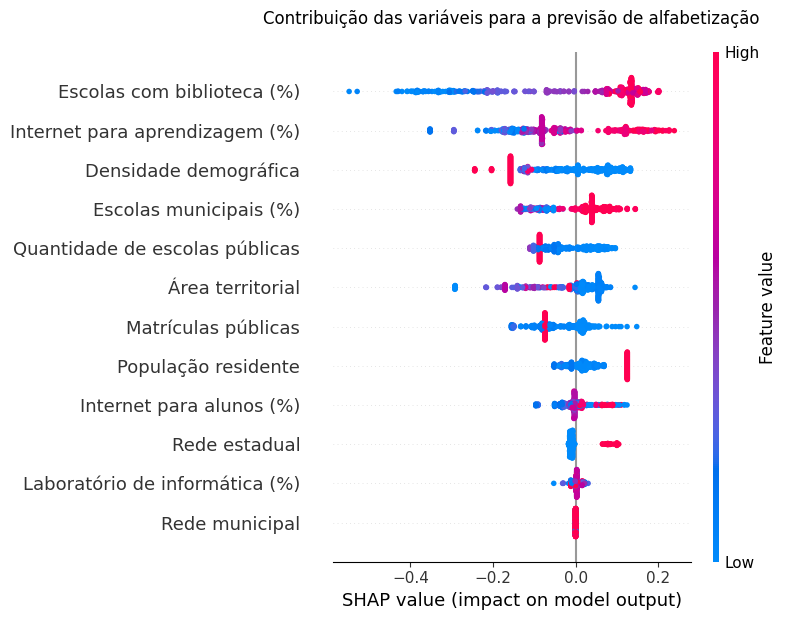

In [18]:
import matplotlib.pyplot as plt

# criando nomes mais fáceis de interpretar
nomes_grafico = [
    "População residente",
    "Área territorial",
    "Densidade demográfica",
    "Quantidade de escolas públicas",
    "Matrículas públicas",
    "Escolas com biblioteca (%)",
    "Internet para alunos (%)",
    "Internet para aprendizagem (%)",
    "Laboratório de informática (%)",
    "Escolas municipais (%)",
    "Rede estadual",
    "Rede municipal",
]

# conferindo a quantidade de nomes
assert len(nomes_grafico) == X_shap.shape[1]

# criando o gráfico SHAP
shap.summary_plot(
    shap_values=valores_shap.values,
    features=X_shap,
    feature_names=nomes_grafico,
    max_display=12,
    show=False,
)

plt.title(
    "Contribuição das variáveis para a previsão de alfabetização",
    pad=20,
)

plt.tight_layout()
plt.show()

### 10.3. Interpretação global dos valores SHAP

A análise SHAP foi realizada com uma amostra de 500 alunos do conjunto de validação de 2023, utilizando o HistGradientBoosting.

O gráfico Beeswarm mostrou que as variáveis com maiores contribuições para as previsões incluem:

- Proporção de escolas com biblioteca ou sala de leitura.
- Proporção de escolas com internet para aprendizagem.
- Densidade demográfica.
- Proporção de escolas municipais.

A proporção de escolas com biblioteca apresentou um padrão no qual valores mais altos tenderam a contribuir positivamente para a previsão de alfabetização, enquanto valores mais baixos tenderam a contribuir negativamente.

Comportamento semelhante foi observado para internet destinada à aprendizagem.

A densidade demográfica apresentou um padrão diferente, com valores mais elevados frequentemente associados a contribuições negativas para a previsão de alfabetização.

Esses resultados são consistentes com a importância preditiva identificada anteriormente, especialmente para bibliotecas e internet para aprendizagem.

Entretanto, os valores SHAP explicam o comportamento do modelo, e não os efeitos causais das características municipais sobre a alfabetização.

A interpretação deve considerar a baixa capacidade discriminativa do modelo, a correlação entre variáveis e a natureza agregada dos indicadores utilizados.

Probabilidade de não alfabetização: 64.36%
Probabilidade de alfabetização: 35.64%


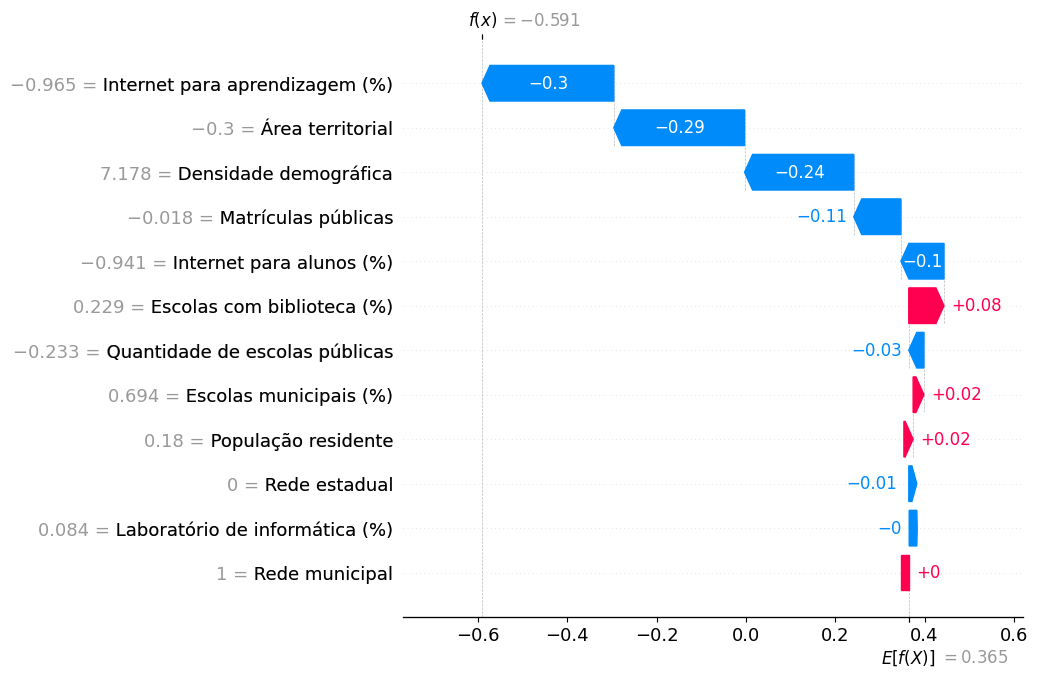

In [19]:
# selecionando o primeiro aluno da amostra SHAP
indice_aluno = 0

# criando a explicação individual com nomes legíveis
explicacao_aluno = shap.Explanation(
    values=valores_shap.values[indice_aluno],
    base_values=valores_shap.base_values[indice_aluno],
    data=X_shap[indice_aluno],
    feature_names=nomes_grafico,
)

# verificando a probabilidade prevista pelo modelo
probabilidade = modelo_hgb_simples.predict_proba(
    amostra_shap.iloc[[indice_aluno]]
)[0]

print(f"Probabilidade de não alfabetização: {probabilidade[0]:.2%}")
print(f"Probabilidade de alfabetização: {probabilidade[1]:.2%}")

# visualizando a contribuição de cada variável
shap.plots.waterfall(
    explicacao_aluno,
    max_display=12,
    show=False,
)

plt.show()

## 11. Auditoria temporal das variáveis

Antes da avaliação final, serão verificados os anos de referência dos dados territoriais e educacionais integrados à base analítica.

O objetivo é identificar possíveis problemas de disponibilidade temporal das informações, evitando utilizar dados que ainda não estariam disponíveis no momento da previsão.

A avaliação de 2024 permanecerá reservada até a conclusão dessa verificação.

In [20]:
# carregando os anos de referência das fontes
referencias = pd.read_parquet(
    caminho,
    columns=[
        "ano",
        "id_municipio",
        "ano_censo",
        "ano_referencia_ibge",
    ],
)

# mantendo uma linha por município e ano
referencias = referencias.drop_duplicates()

# verificando os anos utilizados em cada avaliação
resumo_referencias = (
    referencias.groupby(
        ["ano", "ano_censo", "ano_referencia_ibge"]
    )
    .agg(
        municipios=("id_municipio", "nunique")
    )
    .reset_index()
)

print("Referências temporais das fontes:")
print(resumo_referencias.to_string(index=False))

Referências temporais das fontes:
 ano  ano_censo  ano_referencia_ibge  municipios
2023       2022                 2022        4871
2024       2023                 2022        5517


### 11.1. Resultados da auditoria temporal

A base analítica utiliza indicadores do Censo Escolar de 2022 para as avaliações de 2023 e indicadores do Censo Escolar de 2023 para as avaliações de 2024.

Os indicadores territoriais do IBGE possuem referência ao Censo Demográfico 2022 em ambos os anos.

As divulgações oficiais indicam que os resultados do Censo Escolar foram disponibilizados no ano seguinte ao de referência. Os primeiros resultados de população e densidade do Censo Demográfico 2022 foram divulgados em junho de 2023.

Portanto, a modelagem assume um cenário retrospectivo de previsão realizado após a disponibilização dessas informações e antes do conhecimento do resultado individual da avaliação.

O ano de referência não garante, isoladamente, a disponibilidade histórica dos valores. A data exata da avaliação e a versão dos dados consultados constituem limitações dessa simulação.

A variável de proficiência e os indicadores agregados de alfabetização do próprio ano permanecem excluídos das features para evitar vazamento direto do resultado.

O teste de 2024 será utilizado apenas após a definição do modelo, sem ajustes posteriores baseados em seu desempenho.

In [21]:
from sklearn.base import clone

# reconstruindo a configuração escolhida
modelo_final = clone(modelo_hgb_simples)

# reunindo todos os dados públicos de 2023
X_final_treino = dados_2023[features].copy()
y_final_treino = dados_2023["alfabetizado"].copy()

# treinando com todos os registros de 2023
modelo_final.fit(X_final_treino, y_final_treino)

# conferindo o treinamento
print("Modelo final treinado com sucesso!")
print("Alunos utilizados:", len(X_final_treino))
print("Features utilizadas:", len(features))
print("Anos utilizados:", sorted(dados_2023["ano"].unique()))
print("Modelo:", modelo_final.named_steps["modelo"])

Modelo final treinado com sucesso!
Alunos utilizados: 1502809
Features utilizadas: 11
Anos utilizados: [np.int64(2023)]
Modelo: HistGradientBoostingClassifier(early_stopping=False, l2_regularization=5.0,
                               learning_rate=0.05, max_iter=150,
                               max_leaf_nodes=7, min_samples_leaf=100,
                               random_state=42)



## 12. Avaliação temporal final — 2024

Após a seleção dos hiperparâmetros, o HistGradientBoosting foi treinado novamente utilizando todos os registros válidos das redes públicas de 2023.

A avaliação final será realizada nos alunos avaliados em 2024, que permaneceram separados durante as etapas de treinamento, validação, otimização e interpretabilidade.

O objetivo é verificar a capacidade de generalização temporal do modelo.

Serão avaliadas as seguintes métricas:

- Acurácia e balanced accuracy;
- Precision, recall e F1-score por classe;
- Matriz de confusão;
- ROC-AUC;
- Average Precision.

A classe não alfabetizado (0) será considerada a classe de interesse nas análises de risco.

Para a classificação final, será utilizado o limiar padrão de probabilidade de 0,50. Esse limiar não será ajustado com base nos resultados de 2024.

O desempenho será interpretado considerando as limitações da base, especialmente a utilização de indicadores municipais para realizar previsões individuais.


In [22]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)

# conferindo se estamos avaliando somente o ano de 2024
assert (dados_2024["ano"] == 2024).all()

# recuperando o conjunto de teste
X_teste_final = dados_2024[features].copy()
y_teste_final = dados_2024["alfabetizado"].copy()

# gerando as classificações do modelo final
previsoes_finais = modelo_final.predict(X_teste_final)

# identificando a classe não alfabetizado (0)
classes = list(modelo_final.named_steps["modelo"].classes_)
indice_classe_0 = classes.index(0)

# obtendo as probabilidades de não alfabetização
probabilidades_finais = modelo_final.predict_proba(
    X_teste_final
)[:, indice_classe_0]

# definindo a classe de interesse para ROC-AUC e AP
y_risco_teste = (y_teste_final == 0).astype(int)

# calculando as métricas
acuracia_final = accuracy_score(
    y_teste_final, previsoes_finais
)

balanced_accuracy_final = balanced_accuracy_score(
    y_teste_final, previsoes_finais
)

roc_auc_final = roc_auc_score(
    y_risco_teste, probabilidades_finais
)

ap_final = average_precision_score(
    y_risco_teste, probabilidades_finais
)

prevalencia_final = y_risco_teste.mean()

# apresentando os resultados
print("AVALIAÇÃO TEMPORAL FINAL — 2024")

print("\nAlunos avaliados:", len(y_teste_final))

print(f"\nAcurácia: {acuracia_final:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_final:.4f}")
print(f"ROC-AUC: {roc_auc_final:.4f}")
print(f"Average Precision: {ap_final:.4f}")
print(f"Prevalência de não alfabetizados: {prevalencia_final:.4f}")

print("\nRelatório de classificação:")
print(
    classification_report(
        y_teste_final,
        previsoes_finais,
        labels=[0, 1],
        target_names=["Não alfabetizado", "Alfabetizado"],
        digits=4,
        zero_division=0,
    )
)

print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_teste_final,
        previsoes_finais,
        labels=[0, 1],
    )
)

AVALIAÇÃO TEMPORAL FINAL — 2024

Alunos avaliados: 1851828

Acurácia: 0.6067
Balanced Accuracy: 0.5315
ROC-AUC: 0.5906
Average Precision: 0.4833
Prevalência de não alfabetizados: 0.4022

Relatório de classificação:
                  precision    recall  f1-score   support

Não alfabetizado     0.5407    0.1472    0.2314    744725
    Alfabetizado     0.6149    0.9159    0.7358   1107103

        accuracy                         0.6067   1851828
       macro avg     0.5778    0.5315    0.4836   1851828
    weighted avg     0.5850    0.6067    0.5330   1851828


Matriz de confusão:
[[ 109651  635074]
 [  93160 1013943]]



### 12.1. Resultados da avaliação temporal final

O HistGradientBoosting foi treinado com 1.502.809 registros de alunos das redes públicas avaliados em 2023 e testado em 1.851.828 registros de 2024.

O modelo apresentou:

- Acurácia: 60,67%.
- Balanced Accuracy: 53,15%.
- ROC-AUC: 0,5906.
- Average Precision: 0,4833.
- Recall da classe não alfabetizado: 14,72%.
- F1-score da classe não alfabetizado: 0,2314.

O ROC-AUC permaneceu próximo ao resultado médio da validação cruzada por município realizada em 2023 (0,5813), sugerindo alguma estabilidade temporal da capacidade discriminativa.

Entretanto, o desempenho geral permaneceu limitado.

Entre os 744.725 alunos não alfabetizados presentes no teste, 635.074 não foram identificados pelo modelo utilizando o limiar padrão de classificação.

A acurácia também apresentou ganho pequeno em relação à estratégia de prever sempre a classe majoritária.

Esses resultados indicam que o modelo aprendeu algum sinal preditivo a partir dos indicadores territoriais e educacionais, mas não possui desempenho adequado para orientar decisões individuais de intervenção.

Uma limitação central é a utilização predominante de variáveis municipais para prever resultados individuais.

O conjunto de teste de 2024 não será utilizado para novos ajustes de hiperparâmetros, seleção de features ou escolha de limiares.


In [23]:
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss

# construindo a referência com a prevalência de 2023
prevalencia_treino = (y_final_treino == 0).mean()

# avaliando o erro das probabilidades previstas
brier_modelo = brier_score_loss(
    y_risco_teste,
    probabilidades_finais,
)

# comparando com uma previsão constante baseada em 2023
probabilidades_referencia = np.full(
    len(y_risco_teste),
    prevalencia_treino,
)

brier_referencia = brier_score_loss(
    y_risco_teste,
    probabilidades_referencia,
)

print(f"Brier Score do modelo: {brier_modelo:.4f}")
print(f"Brier Score da referência: {brier_referencia:.4f}")

# organizando as probabilidades e os resultados reais
df_calibracao = pd.DataFrame({
    "probabilidade_prevista": probabilidades_finais,
    "nao_alfabetizado_real": y_risco_teste.to_numpy(),
})

# dividindo as previsões em cinco grupos
df_calibracao["faixa_risco"] = pd.qcut(
    df_calibracao["probabilidade_prevista"],
    q=5,
    duplicates="drop",
)

# comparando probabilidades previstas e proporções observadas
resumo_calibracao = (
    df_calibracao.groupby("faixa_risco", observed=True)
    .agg(
        alunos=("nao_alfabetizado_real", "size"),
        risco_medio_previsto=("probabilidade_prevista", "mean"),
        proporcao_real=("nao_alfabetizado_real", "mean"),
    )
    .reset_index()
)

print("\nCalibração por faixa de risco:")
print(resumo_calibracao.round(4).to_string(index=False))

Brier Score do modelo: 0.2346
Brier Score da referência: 0.2406

Calibração por faixa de risco:
   faixa_risco  alunos  risco_medio_previsto  proporcao_real
 (0.217, 0.33]  371032                0.2938          0.3040
  (0.33, 0.38]  369823                0.3541          0.3550
 (0.38, 0.426]  380489                0.4085          0.3885
(0.426, 0.475]  385651                0.4521          0.4523
 (0.475, 0.59]  344833                0.5099          0.5172



### 12.2. Avaliação da calibração das probabilidades

A calibração foi investigada no conjunto de teste temporal de 2024, utilizando o Brier Score e a comparação entre probabilidades previstas e proporções reais de não alfabetização.

O HistGradientBoosting apresentou:

- Brier Score: 0,2346.
- Brier Score da referência constante, baseada na prevalência de 2023: 0,2406.

O modelo apresentou redução de aproximadamente 2,5% no Brier Score em relação à referência.

Na análise por cinco faixas de risco, as probabilidades médias previstas ficaram relativamente próximas das proporções reais observadas, com diferença máxima aproximada de 2 pontos percentuais.

Os resultados indicam calibração agregada razoável nas faixas analisadas, mas não garantem confiabilidade das probabilidades individuais.

Considerando a capacidade discriminativa limitada do modelo, suas previsões não devem ser utilizadas isoladamente para diagnósticos individuais ou decisões automatizadas de intervenção educacional.

A avaliação temporal foi utilizada exclusivamente para diagnosticar o desempenho do modelo final, sem novos ajustes de hiperparâmetros ou limiares.


In [24]:
# organizando as previsões individuais de 2024
df_risco_2024 = dados_2024[
    ["id_municipio", "rede_codigo", "alfabetizado"]
].copy()

# garantindo que a ordem dos registros corresponde às previsões
assert df_risco_2024.index.equals(X_teste_final.index)
assert len(df_risco_2024) == len(probabilidades_finais)

# adicionando a probabilidade prevista de não alfabetização
df_risco_2024["risco_previsto"] = probabilidades_finais

# selecionando somente a rede municipal
df_risco_municipal = df_risco_2024[
    df_risco_2024["rede_codigo"] == "3"
].copy()

# agregando os resultados por município
risco_municipal = (
    df_risco_municipal.groupby("id_municipio")
    .agg(
        alunos_avaliados=("alfabetizado", "size"),
        risco_medio_previsto=("risco_previsto", "mean"),
        taxa_alfabetizacao_observada=("alfabetizado", "mean"),
    )
    .reset_index()
)

# calculando a proporção observada de não alfabetizados
risco_municipal["risco_observado"] = (
    1 - risco_municipal["taxa_alfabetizacao_observada"]
)

# verificando a cobertura municipal
print("Total de municípios:", len(risco_municipal))

print("\nDistribuição de alunos por município:")
print(
    risco_municipal["alunos_avaliados"]
    .describe()
    .round(2)
)

# selecionando municípios com pelo menos 100 alunos avaliados
risco_municipal_100 = risco_municipal[
    risco_municipal["alunos_avaliados"] >= 100
].copy()

print(
    "\nMunicípios com pelo menos 100 alunos:",
    len(risco_municipal_100),
)

# investigando os municípios com maiores riscos previstos
print("\n10 municípios com maiores riscos previstos:")
print(
    risco_municipal_100.nlargest(
        10,
        "risco_medio_previsto",
    )[
        [
            "id_municipio",
            "alunos_avaliados",
            "risco_medio_previsto",
            "risco_observado",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

Total de municípios: 5450

Distribuição de alunos por município:
count     5450.00
mean       295.55
std       1101.75
min          6.00
25%         50.00
50%        103.00
75%        231.00
max      43340.00
Name: alunos_avaliados, dtype: float64

Municípios com pelo menos 100 alunos: 2781

10 municípios com maiores riscos previstos:
id_municipio  alunos_avaliados  risco_medio_previsto  risco_observado
     3305109              2543                0.5901           0.6394
     2907202               430                0.5836           0.7907
     1504703               769                0.5754           0.6580
     2918407              2494                0.5742           0.7069
     2910800              3528                0.5679           0.6681
     1303809               340                0.5649           0.6794
     2903201              1654                0.5588           0.6391
     1501105               276                0.5568           0.4638
     1504505               354   

### 13.1. Avaliação das previsões municipais

A qualidade das estimativas municipais será investigada por meio da comparação entre o risco médio previsto e a proporção observada de alunos não alfabetizados em 2024.

Serão utilizadas as correlações de Pearson e Spearman para avaliar a associação entre os valores previstos e observados.

Também será calculado o erro absoluto médio (MAE) entre as taxas municipais.

A análise será realizada nos municípios da rede municipal com pelo menos 100 alunos avaliados, de forma retrospectiva e sem reajustar o modelo.

In [25]:
import numpy as np

# selecionando as estimativas e os resultados municipais
comparacao_municipal = risco_municipal_100[
    [
        "id_municipio",
        "alunos_avaliados",
        "risco_medio_previsto",
        "risco_observado",
    ]
].copy()

# calculando a correlação de Pearson
pearson_municipal = comparacao_municipal[
    ["risco_medio_previsto", "risco_observado"]
].corr(method="pearson").iloc[0, 1]

# calculando a correlação de Spearman
spearman_municipal = comparacao_municipal[
    ["risco_medio_previsto", "risco_observado"]
].corr(method="spearman").iloc[0, 1]

# calculando o erro absoluto por município
comparacao_municipal["erro_absoluto"] = (
    comparacao_municipal["risco_medio_previsto"]
    - comparacao_municipal["risco_observado"]
).abs()

# calculando o erro médio com peso igual para cada município
mae_municipal = comparacao_municipal["erro_absoluto"].mean()

# calculando o erro médio ponderado pela quantidade de alunos
mae_ponderado = np.average(
    comparacao_municipal["erro_absoluto"],
    weights=comparacao_municipal["alunos_avaliados"],
)

# apresentando os resultados
print("Municípios analisados:", len(comparacao_municipal))

print(f"\nCorrelação de Pearson: {pearson_municipal:.4f}")
print(f"Correlação de Spearman: {spearman_municipal:.4f}")

print(f"\nMAE municipal: {mae_municipal * 100:.2f} p.p.")
print(f"MAE ponderado: {mae_ponderado * 100:.2f} p.p.")

print("\nDistribuição dos riscos previstos:")
print(
    comparacao_municipal["risco_medio_previsto"]
    .describe()
    .round(4)
)

print("\nDistribuição dos riscos observados:")
print(
    comparacao_municipal["risco_observado"]
    .describe()
    .round(4)
)

Municípios analisados: 2781

Correlação de Pearson: 0.4220
Correlação de Spearman: 0.4214

MAE municipal: 13.34 p.p.
MAE ponderado: 10.34 p.p.

Distribuição dos riscos previstos:
count    2781.0000
mean        0.3952
std         0.0814
min         0.2177
25%         0.3311
50%         0.3898
75%         0.4652
max         0.5901
Name: risco_medio_previsto, dtype: float64

Distribuição dos riscos observados:
count    2781.0000
mean        0.3902
std         0.1813
min         0.0000
25%         0.2550
50%         0.3864
75%         0.5280
max         0.8819
Name: risco_observado, dtype: float64



### 13.2. Resultados da avaliação municipal

A avaliação territorial foi realizada em 2.781 municípios com pelo menos 100 alunos avaliados na rede municipal em 2024.

Os resultados foram:

- Correlação de Pearson: 0,4220.
- Correlação de Spearman: 0,4214.
- MAE municipal: 13,34 pontos percentuais.
- MAE ponderado pelo número de alunos: 10,34 pontos percentuais.

As correlações indicam uma associação positiva moderada entre o risco médio previsto e a proporção observada de alunos não alfabetizados.

Entretanto, o erro absoluto médio revela limitações importantes na precisão das estimativas municipais.

O desvio-padrão dos riscos previstos foi de aproximadamente 8,14 pontos percentuais, enquanto o dos riscos observados foi de 18,13 pontos percentuais.

Essa diferença indica que o modelo produz estimativas mais concentradas e apresenta dificuldade para representar toda a heterogeneidade dos resultados municipais.

Portanto, as previsões não devem ser utilizadas isoladamente para definir prioridades educacionais.

Na próxima etapa, os resultados serão relacionados às metas municipais de alfabetização, permitindo investigar a situação educacional dos territórios a partir de indicadores observados e das estimativas do modelo.

A análise será retrospectiva e não permitirá inferir que o risco estimado representa a probabilidade de um município descumprir metas futuras.



### 13.3. Integração com as metas municipais de alfabetização

Nesta etapa, será utilizada a tabela Gold de comparação entre os resultados municipais de alfabetização e as metas educacionais, construída na Fase 2.

O objetivo é integrar os indicadores observados de cumprimento das metas às estimativas de risco produzidas pelo modelo.

A análise buscará identificar municípios com resultados educacionais preocupantes e investigar como esses resultados se relacionam às previsões realizadas.

A comparação será restrita ao ano de 2024 e terá caráter retrospectivo.


In [26]:
from pathlib import Path
import pandas as pd

# localizando a tabela Gold de metas municipais
caminho_metas = Path(
    "data/gold/comparativo_metas_municipio_brasil.parquet"
)

if not caminho_metas.exists():
    caminho_metas = Path(
        "../data/gold/comparativo_metas_municipio_brasil.parquet"
    )

# carregando a tabela de metas
df_metas = pd.read_parquet(caminho_metas)

# verificando sua estrutura
print("Dimensão da tabela:", df_metas.shape)

print("\nColunas disponíveis:")
print(df_metas.dtypes.to_string())

print("\nPrimeiros registros:")
print(df_metas.head(3).to_string(index=False))

Dimensão da tabela: (10704, 13)

Colunas disponíveis:
ano                                         int64
id_municipio                       string[python]
rede_descricao                     string[python]
taxa_alfabetizacao                        float64
meta_referencia_ano                       float64
distancia_para_meta_municipio             float64
status_meta_municipio                      object
taxa_alfabetizacao_brasil                 float64
meta_referencia_brasil                    float64
diferenca_taxa_municipio_brasil           float64
nivel_alfabetizacao                       float64
percentual_participacao                   float64
percentual_participacao_brasil            float64

Primeiros registros:
 ano id_municipio rede_descricao  taxa_alfabetizacao  meta_referencia_ano  distancia_para_meta_municipio   status_meta_municipio  taxa_alfabetizacao_brasil  meta_referencia_brasil  diferenca_taxa_municipio_brasil  nivel_alfabetizacao  percentual_participacao  percentual_par


### 13.4. Cruzamento das previsões com as metas municipais

As previsões agregadas por município serão integradas à tabela Gold de metas de alfabetização de 2024, utilizando o código IBGE do município como chave.

A análise utilizará os municípios da rede municipal com pelo menos 100 alunos avaliados.

Antes de comparar os indicadores, serão verificadas:

- A existência de registros duplicados por município.
- A quantidade de municípios com correspondência entre as tabelas.
- A disponibilidade dos resultados e das metas municipais.
- A distribuição dos municípios conforme o status de cumprimento da meta.

Essa verificação é necessária para evitar interpretações baseadas em cruzamentos incompletos ou inconsistentes.


In [27]:
# selecionando as informações municipais de 2024
metas_2024 = df_metas.loc[
    df_metas["ano"] == 2024,
    [
        "id_municipio",
        "taxa_alfabetizacao",
        "meta_referencia_ano",
        "distancia_para_meta_municipio",
        "status_meta_municipio",
        "percentual_participacao",
    ],
].copy()

# verificando possíveis duplicidades por município
duplicados = metas_2024["id_municipio"].duplicated().sum()

print("Municípios na tabela de metas de 2024:", len(metas_2024))
print("Municípios duplicados:", duplicados)

# garantindo que cada município aparece uma única vez
assert duplicados == 0

# integrando as previsões às metas
analise_metas = comparacao_municipal.merge(
    metas_2024,
    on="id_municipio",
    how="left",
    validate="one_to_one",
    indicator=True,
)

# verificando a cobertura do cruzamento
print("\nCobertura do cruzamento:")
print(analise_metas["_merge"].value_counts().to_string())

# removendo a coluna auxiliar
analise_metas = analise_metas.drop(columns="_merge")

# verificando os resultados e as metas disponíveis
print("\nMunicípios com resultado de alfabetização:",
      analise_metas["taxa_alfabetizacao"].notna().sum())

print("Municípios com meta de referência:",
      analise_metas["meta_referencia_ano"].notna().sum())

# identificando o status das metas
print("\nDistribuição do status das metas:")
print(
    analise_metas["status_meta_municipio"]
    .value_counts(dropna=False)
    .to_string()
)

Municípios na tabela de metas de 2024: 5352
Municípios duplicados: 0

Cobertura do cruzamento:
_merge
both          2743
left_only       38
right_only       0

Municípios com resultado de alfabetização: 2743
Municípios com meta de referência: 2696

Distribuição do status das metas:
status_meta_municipio
atingiu_ou_superou_meta    1395
abaixo_da_meta             1301
sem_meta_ou_resultado        47
NaN                          38



### 13.5. Resultados da integração com as metas municipais

A integração das previsões municipais com a tabela Gold de metas de alfabetização de 2024 apresentou os seguintes resultados:

- Municípios inicialmente selecionados: 2.781.
- Municípios com correspondência na tabela de metas: 2.743.
- Municípios sem correspondência: 38.
- Municípios sem meta ou resultado comparável: 47.
- Municípios com metas comparáveis: 2.696.

Entre os municípios com metas comparáveis:

- 1.395 (51,7%) atingiram ou superaram a meta.
- 1.301 (48,3%) ficaram abaixo da meta.

A cobertura do cruzamento foi elevada, permitindo avançar para uma análise retrospectiva da relação entre risco previsto e cumprimento das metas.

Os municípios sem correspondência ou sem meta comparável serão excluídos apenas desta análise específica.

O risco previsto representa a probabilidade estimada de não alfabetização, e não a probabilidade de descumprimento da meta municipal.



### 13.6. Relação entre risco previsto e cumprimento das metas

Nesta etapa, serão comparados os riscos médios previstos dos municípios que atingiram ou superaram suas metas com os daqueles que ficaram abaixo delas.

Também será investigada a associação entre o risco previsto e a distância entre a taxa observada de alfabetização e a meta municipal.

Essa análise permitirá verificar se o modelo apresenta alguma utilidade descritiva para diferenciar os municípios conforme sua situação educacional.

A comparação será retrospectiva e não será utilizada para reajustar o modelo.


In [28]:
# selecionando somente municípios com metas comparáveis
metas_comparaveis = analise_metas[
    analise_metas["status_meta_municipio"].isin([
        "atingiu_ou_superou_meta",
        "abaixo_da_meta",
    ])
].copy()

# garantindo que a distância até a meta está disponível
metas_comparaveis = metas_comparaveis.dropna(
    subset=[
        "risco_medio_previsto",
        "distancia_para_meta_municipio",
    ]
)

# comparando os dois grupos
resumo_status_meta = (
    metas_comparaveis
    .groupby("status_meta_municipio")
    .agg(
        municipios=("id_municipio", "size"),
        risco_previsto_medio=("risco_medio_previsto", "mean"),
        risco_previsto_mediano=("risco_medio_previsto", "median"),
        risco_observado_medio=("risco_observado", "mean"),
        distancia_media_meta=("distancia_para_meta_municipio", "mean"),
    )
    .reset_index()
)

print("Comparação por situação da meta:")
print(resumo_status_meta.round(4).to_string(index=False))

# verificando a associação entre risco previsto e distância até a meta
correlacao_meta_pearson = metas_comparaveis[
    ["risco_medio_previsto", "distancia_para_meta_municipio"]
].corr(method="pearson").iloc[0, 1]

correlacao_meta_spearman = metas_comparaveis[
    ["risco_medio_previsto", "distancia_para_meta_municipio"]
].corr(method="spearman").iloc[0, 1]

print("\nMunicípios analisados:", len(metas_comparaveis))

print(
    f"Correlação de Pearson (risco × distância até a meta): "
    f"{correlacao_meta_pearson:.4f}"
)

print(
    f"Correlação de Spearman (risco × distância até a meta): "
    f"{correlacao_meta_spearman:.4f}"
)

Comparação por situação da meta:
  status_meta_municipio  municipios  risco_previsto_medio  risco_previsto_mediano  risco_observado_medio  distancia_media_meta
         abaixo_da_meta        1301                0.4039                  0.4027                 0.4907               -8.8553
atingiu_ou_superou_meta        1395                0.3842                  0.3776                 0.2887                9.3324

Municípios analisados: 2696
Correlação de Pearson (risco × distância até a meta): -0.1116
Correlação de Spearman (risco × distância até a meta): -0.1325



### 13.7. Resultados da relação entre risco previsto e metas municipais

A análise foi realizada em 2.696 municípios com metas comparáveis em 2024.

Entre os municípios que ficaram abaixo da meta, o risco médio previsto de não alfabetização foi de 40,39%, enquanto o risco observado foi de 49,07%.

Nos municípios que atingiram ou superaram a meta, o risco médio previsto foi de 38,42%, enquanto o risco observado foi de 28,87%.

A diferença entre os riscos médios previstos dos dois grupos foi de apenas 1,97 ponto percentual, enquanto a diferença entre os riscos observados foi de 20,20 pontos percentuais.

A correlação entre o risco previsto e a distância até a meta municipal foi:

- Pearson: -0,1116.
- Spearman: -0,1325.

Os resultados indicam uma associação negativa muito fraca entre o risco estimado de não alfabetização e a distância até a meta municipal.

Assim, embora o modelo apresente algum sinal preditivo sobre a alfabetização, suas estimativas não são suficientes para identificar com precisão os municípios com maiores dificuldades de cumprimento das metas.

Para a aplicação estratégica, serão priorizados indicadores educacionais observados, como a distância até a meta, a taxa de alfabetização e a participação na avaliação.

As previsões do modelo serão utilizadas apenas como informação complementar, respeitando suas limitações.



### 13.8. Identificação de municípios com maiores déficits em relação às metas

Serão selecionados os municípios que ficaram abaixo de suas metas de alfabetização em 2024.

Para cada município, serão analisados:

- Taxa de alfabetização observada.
- Meta municipal de referência.
- Déficit em relação à meta, em pontos percentuais.
- Quantidade de alunos presentes na base analítica.
- Percentual de participação na avaliação.
- Risco médio estimado pelo modelo.

O ranking será organizado pelo tamanho do déficit em relação à meta.

Essa classificação representa uma análise retrospectiva de resultados educacionais, e não uma previsão de dificuldades futuras.

O número de alunos da base será utilizado para contextualização, sem representar necessariamente a totalidade dos estudantes do município.


In [29]:
# selecionando os municípios que ficaram abaixo da meta
municipios_abaixo_meta = metas_comparaveis.loc[
    metas_comparaveis["status_meta_municipio"] == "abaixo_da_meta"
].copy()

# convertendo a distância negativa em déficit positivo
municipios_abaixo_meta["deficit_meta_pp"] = (
    -municipios_abaixo_meta["distancia_para_meta_municipio"]
)

# convertendo o risco estimado para porcentagem
municipios_abaixo_meta["risco_previsto_pct"] = (
    municipios_abaixo_meta["risco_medio_previsto"] * 100
)

# ordenando pelo maior déficit em relação à meta
ranking_deficit = municipios_abaixo_meta.sort_values(
    by="deficit_meta_pp",
    ascending=False,
).copy()

print("Municípios abaixo da meta:", len(ranking_deficit))

print("\nDistribuição dos déficits em relação à meta:")
print(
    ranking_deficit["deficit_meta_pp"]
    .describe()
    .round(2)
)

print("\n10 municípios com maiores déficits:")
print(
    ranking_deficit[
        [
            "id_municipio",
            "alunos_avaliados",
            "taxa_alfabetizacao",
            "meta_referencia_ano",
            "deficit_meta_pp",
            "percentual_participacao",
            "risco_previsto_pct",
        ]
    ]
    .head(10)
    .round(2)
    .to_string(index=False)
)

Municípios abaixo da meta: 1301

Distribuição dos déficits em relação à meta:
count    1301.00
mean        8.86
std         7.48
min         0.02
25%         3.17
50%         6.79
75%        12.45
max        45.37
Name: deficit_meta_pp, dtype: float64

10 municípios com maiores déficits:
id_municipio  alunos_avaliados  taxa_alfabetizacao  meta_referencia_ano  deficit_meta_pp  percentual_participacao  risco_previsto_pct
     2100808               109               34.63                80.00            45.37                    76.76               40.30
     2106607               269               34.52                73.54            39.02                    89.67               46.08
     2112605               277               38.63                77.24            38.61                    93.58               51.09
     3529708               155               29.09                66.88            37.79                    79.49               37.45
     4318903               169           


### 13.9. Resultados do ranking de déficits municipais

Entre os 2.696 municípios com metas comparáveis, 1.301 ficaram abaixo de suas metas de alfabetização em 2024.

A distribuição dos déficits apresentou:

- Déficit médio: 8,86 pontos percentuais.
- Déficit mediano: 6,79 pontos percentuais.
- Terceiro quartil: 12,45 pontos percentuais.
- Maior déficit: 45,37 pontos percentuais.

Os resultados evidenciam diferenças expressivas na distância dos municípios em relação às metas educacionais.

O município de código IBGE 2100808 apresentou o maior déficit, com taxa de alfabetização de 34,63% diante de uma meta de 80%.

Entretanto, seu risco médio previsto de não alfabetização foi de 40,30%, evidenciando que as previsões do modelo não reproduzem necessariamente a intensidade dos déficits observados.

Essa diferença é consistente com os resultados anteriores, que demonstraram associação fraca entre risco previsto e distância até as metas.

A interpretação dos municípios com maiores déficits também deve considerar o número de alunos avaliados e o percentual de participação.

O ranking representa uma análise retrospectiva dos resultados de 2024 e não deve ser utilizado isoladamente para determinar a distribuição de recursos educacionais.



### 13.10. Concordância entre os rankings de risco e déficit

Será investigada a concordância entre dois critérios de ordenação dos municípios:

1. Maior déficit observado em relação à meta de alfabetização.
2. Maior risco médio de não alfabetização previsto pelo modelo.

A comparação será realizada entre os 1.301 municípios que ficaram abaixo de suas metas em 2024.

Serão avaliadas a interseção entre os dez primeiros municípios de cada ranking e a sobreposição entre os 10% de municípios com maiores valores em cada critério.

O objetivo é verificar se o ranking preditivo identifica os mesmos territórios destacados pelos indicadores observados.

Essa comparação possui caráter diagnóstico e não será utilizada para modificar o modelo.


In [30]:
import numpy as np

# base comum: municípios que ficaram abaixo da meta
base_rankings = municipios_abaixo_meta.copy()

# criando a posição de cada município nos dois rankings
base_rankings["posicao_deficit"] = (
    base_rankings["deficit_meta_pp"]
    .rank(ascending=False, method="min")
    .astype(int)
)

base_rankings["posicao_risco"] = (
    base_rankings["risco_medio_previsto"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# selecionando os 10 primeiros de cada ranking
top10_deficit = base_rankings.nlargest(
    10, "deficit_meta_pp"
)

top10_risco = base_rankings.nlargest(
    10, "risco_medio_previsto"
)

# calculando a interseção entre os rankings
ids_deficit = set(top10_deficit["id_municipio"])
ids_risco = set(top10_risco["id_municipio"])

intersecao_top10 = ids_deficit & ids_risco

print("Municípios presentes nos dois TOP 10:",
      len(intersecao_top10))

# comparando os 10% mais críticos de cada ranking
total_municipios = len(base_rankings)
quantidade_top10pct = int(np.ceil(total_municipios * 0.10))

top_deficit_10pct = set(
    base_rankings.nlargest(
        quantidade_top10pct, "deficit_meta_pp"
    )["id_municipio"]
)

top_risco_10pct = set(
    base_rankings.nlargest(
        quantidade_top10pct, "risco_medio_previsto"
    )["id_municipio"]
)

intersecao_10pct = top_deficit_10pct & top_risco_10pct

print("\nMunicípios analisados:", total_municipios)
print("Quantidade em cada TOP 10%:", quantidade_top10pct)
print("Municípios presentes nos dois TOP 10%:",
      len(intersecao_10pct))

print(
    "Sobreposição entre os TOP 10%:",
    f"{len(intersecao_10pct) / quantidade_top10pct:.2%}"
)

# verificando a posição de risco dos maiores déficits
print("\nRanking dos 10 maiores déficits:")
print(
    top10_deficit[
        [
            "id_municipio",
            "deficit_meta_pp",
            "risco_previsto_pct",
            "posicao_risco",
        ]
    ]
    .round(2)
    .to_string(index=False)
)

Municípios presentes nos dois TOP 10: 0

Municípios analisados: 1301
Quantidade em cada TOP 10%: 131
Municípios presentes nos dois TOP 10%: 9
Sobreposição entre os TOP 10%: 6.87%

Ranking dos 10 maiores déficits:
id_municipio  deficit_meta_pp  risco_previsto_pct  posicao_risco
     2100808            45.37               40.30            650
     2106607            39.02               46.08            404
     2112605            38.61               51.09            127
     3529708            37.79               37.45            785
     4318903            37.70               31.54           1068
     2108801            37.62               40.83            634
     4304408            36.67               36.89            817
     2516904            35.55               43.30            559
     2924504            34.13               39.48            688
     5005681            33.54               33.24            996



### 13.11. Resultados da comparação entre os rankings

A concordância entre o ranking dos maiores déficits em relação às metas e o ranking dos maiores riscos previstos foi investigada em 1.301 municípios abaixo da meta em 2024.

Os resultados foram:

- Municípios em comum entre os dois TOP 10: 0.
- Municípios selecionados em cada TOP 10%: 131.
- Municípios em comum entre os dois TOP 10%: 9.
- Sobreposição entre os TOP 10%: 6,87%.

Como referência, a sobreposição média esperada entre dois grupos de 131 municípios selecionados aleatoriamente entre 1.301 seria de aproximadamente 13 municípios.

A baixa concordância observada reforça as limitações do modelo para identificar os municípios com maiores déficits em relação às metas.

O município de código IBGE 2100808, que apresentou o maior déficit observado, ocupou apenas a 650ª posição no ranking de risco previsto.

Esses resultados são compatíveis com a associação muito fraca encontrada anteriormente entre risco previsto e distância até a meta.

É importante observar que o modelo foi treinado para estimar o risco de não alfabetização, e não para prever o cumprimento de metas municipais.

Dessa forma, os rankings medem fenômenos relacionados, mas diferentes.

A análise estratégica continuará utilizando prioritariamente os indicadores observados de alfabetização, cumprimento de metas e participação. As previsões serão apresentadas como resultados experimentais complementares.



## 14. Análise territorial dos resultados educacionais

### 14.1. Distribuição do cumprimento das metas por estado

A análise territorial será realizada com os municípios que possuem metas de alfabetização comparáveis em 2024.

Os códigos IBGE municipais serão utilizados para identificar as unidades federativas.

Para cada estado, serão calculados:

- Quantidade de municípios analisados.
- Quantidade e percentual de municípios abaixo da meta.
- Déficit médio entre os municípios abaixo da meta.
- Taxa média municipal de alfabetização.
- Percentual médio de participação na avaliação.

O objetivo é identificar diferenças territoriais no cumprimento das metas e subsidiar análises estratégicas.

Os resultados não devem ser interpretados como indicadores oficiais agregados de cada estado, pois representam apenas os municípios selecionados e utilizam médias municipais não ponderadas.


In [31]:
# identificando a UF pelos dois primeiros dígitos do código IBGE
siglas_uf = {
    "11": "RO", "12": "AC", "13": "AM", "14": "RR",
    "15": "PA", "16": "AP", "17": "TO",
    "21": "MA", "22": "PI", "23": "CE", "24": "RN",
    "25": "PB", "26": "PE", "27": "AL", "28": "SE",
    "29": "BA",
    "31": "MG", "32": "ES", "33": "RJ", "35": "SP",
    "41": "PR", "42": "SC", "43": "RS",
    "50": "MS", "51": "MT", "52": "GO", "53": "DF",
}

# preparando os dados territoriais
dados_uf = metas_comparaveis.copy()

dados_uf["uf"] = (
    dados_uf["id_municipio"].str[:2].map(siglas_uf)
)

assert dados_uf["uf"].notna().all()

# identificando municípios abaixo da meta
dados_uf["abaixo_meta"] = (
    dados_uf["status_meta_municipio"] == "abaixo_da_meta"
)

# calculando o déficit somente para quem ficou abaixo da meta
dados_uf["deficit_abaixo_meta_pp"] = (
    -dados_uf["distancia_para_meta_municipio"]
).where(dados_uf["abaixo_meta"])

# agregando os indicadores por UF
resumo_uf = (
    dados_uf.groupby("uf")
    .agg(
        municipios=("id_municipio", "size"),
        municipios_abaixo_meta=("abaixo_meta", "sum"),
        deficit_medio_pp=("deficit_abaixo_meta_pp", "mean"),
        alfabetizacao_media=("taxa_alfabetizacao", "mean"),
        participacao_media=("percentual_participacao", "mean"),
    )
    .reset_index()
)

# calculando o percentual de municípios abaixo da meta
resumo_uf["pct_abaixo_meta"] = (
    resumo_uf["municipios_abaixo_meta"]
    / resumo_uf["municipios"] * 100
)

# ordenando pelo percentual de municípios abaixo da meta
resumo_uf = resumo_uf.sort_values(
    "pct_abaixo_meta",
    ascending=False,
)

print("Estados analisados:", len(resumo_uf))

print("\nCumprimento das metas por estado:")
print(resumo_uf.round(2).to_string(index=False))

Estados analisados: 24

Cumprimento das metas por estado:
uf  municipios  municipios_abaixo_meta  deficit_medio_pp  alfabetizacao_media  participacao_media  pct_abaixo_meta
RS         100                      99             21.02                48.06               86.01            99.00
BA         260                     219              9.58                35.63               91.56            84.23
AM          41                      31             12.19                45.74               85.42            75.61
PA         124                      85              7.47                48.54               84.89            68.55
PR         206                     133              5.96                72.14               88.49            64.56
AP          13                       8              9.55                48.74               89.57            61.54
RJ          82                      50              4.45                57.69               83.40            60.98
RN          35        


### 14.2. Resultados da análise estadual

A análise do cumprimento das metas de alfabetização em 2024 contemplou 2.696 municípios distribuídos em 24 unidades federativas.

Os estados com maiores percentuais de municípios abaixo da meta foram:

- Rio Grande do Sul: 99,00%, entre 100 municípios analisados.
- Bahia: 84,23%, entre 260 municípios.
- Amazonas: 75,61%, entre 41 municípios.
- Pará: 68,55%, entre 124 municípios.
- Paraná: 64,56%, entre 206 municípios.

O Rio Grande do Sul também apresentou o maior déficit médio entre os municípios abaixo da meta, de 21,02 pontos percentuais.

A Bahia apresentou o maior número absoluto de municípios abaixo da meta na amostra, totalizando 219 municípios.

Entre os resultados mais favoráveis, destacaram-se Ceará (10,00% abaixo da meta), Minas Gerais (16,43%) e Goiás (20,19%).

O Ceará apresentou taxa média municipal de alfabetização de 89,92% e participação média de 98,57%.

Esses resultados evidenciam diferenças territoriais relevantes, mas devem ser interpretados considerando:

- A seleção de municípios com pelo menos 100 alunos avaliados.
- A ausência de algumas unidades federativas após os filtros.
- A utilização de médias municipais não ponderadas.
- As diferenças entre as metas estabelecidas para cada município.
- A impossibilidade de estabelecer relações causais entre os indicadores e os resultados educacionais.

Os indicadores apresentados representam a amostra analisada e não substituem estatísticas oficiais agregadas dos estados.



### 14.3. Análise do cumprimento das metas por região

Os municípios serão agrupados nas cinco grandes regiões brasileiras, utilizando a unidade federativa identificada pelo código IBGE.

Para cada região, serão calculados:

- Quantidade de municípios analisados.
- Quantidade e percentual de municípios abaixo da meta.
- Déficit médio entre os municípios abaixo da meta.
- Taxa média municipal de alfabetização.
- Percentual médio de participação.

A análise permitirá identificar padrões territoriais mais amplos, considerando as limitações de cobertura e representatividade da amostra.


In [32]:
# associando cada UF à sua região brasileira
regioes_uf = {
    "RO": "Norte", "AC": "Norte", "AM": "Norte",
    "RR": "Norte", "PA": "Norte", "AP": "Norte",
    "TO": "Norte",

    "MA": "Nordeste", "PI": "Nordeste",
    "CE": "Nordeste", "RN": "Nordeste",
    "PB": "Nordeste", "PE": "Nordeste",
    "AL": "Nordeste", "SE": "Nordeste",
    "BA": "Nordeste",

    "MG": "Sudeste", "ES": "Sudeste",
    "RJ": "Sudeste", "SP": "Sudeste",

    "PR": "Sul", "SC": "Sul", "RS": "Sul",

    "MS": "Centro-Oeste", "MT": "Centro-Oeste",
    "GO": "Centro-Oeste", "DF": "Centro-Oeste",
}

# criando a coluna de região
dados_regiao = dados_uf.copy()

dados_regiao["regiao"] = (
    dados_regiao["uf"].map(regioes_uf)
)

assert dados_regiao["regiao"].notna().all()

# agregando os indicadores por região
resumo_regiao = (
    dados_regiao.groupby("regiao")
    .agg(
        municipios=("id_municipio", "size"),
        municipios_abaixo_meta=("abaixo_meta", "sum"),
        deficit_medio_pp=("deficit_abaixo_meta_pp", "mean"),
        alfabetizacao_media=("taxa_alfabetizacao", "mean"),
        participacao_media=("percentual_participacao", "mean"),
    )
    .reset_index()
)

# calculando o percentual de municípios abaixo da meta
resumo_regiao["pct_abaixo_meta"] = (
    resumo_regiao["municipios_abaixo_meta"]
    / resumo_regiao["municipios"] * 100
)

# ordenando pelo maior percentual de descumprimento
resumo_regiao = resumo_regiao.sort_values(
    "pct_abaixo_meta",
    ascending=False,
)

print("Regiões analisadas:", len(resumo_regiao))

print("\nCumprimento das metas por região:")
print(
    resumo_regiao
    .round(2)
    .to_string(index=False)
)

Regiões analisadas: 5

Cumprimento das metas por região:
      regiao  municipios  municipios_abaixo_meta  deficit_medio_pp  alfabetizacao_media  participacao_media  pct_abaixo_meta
         Sul         397                     277             11.42                64.71               86.14            69.77
       Norte         245                     150              8.58                51.18               86.31            61.22
    Nordeste        1017                     515              9.52                56.81               93.66            50.64
     Sudeste         781                     287              5.81                66.29               89.90            36.75
Centro-Oeste         256                      72              6.92                67.50               91.79            28.12



### 14.4. Resultados da análise regional

A análise territorial contemplou 2.696 municípios com metas comparáveis em 2024, distribuídos pelas cinco grandes regiões brasileiras.

Os percentuais de municípios abaixo da meta foram:

- Sul: 69,77% (277 de 397 municípios).
- Norte: 61,22% (150 de 245 municípios).
- Nordeste: 50,64% (515 de 1.017 municípios).
- Sudeste: 36,75% (287 de 781 municípios).
- Centro-Oeste: 28,12% (72 de 256 municípios).

O Sul apresentou o maior percentual de municípios abaixo da meta e o maior déficit médio entre os municípios nessa situação, de 11,42 pontos percentuais.

O Norte apresentou a menor taxa média municipal de alfabetização, de 51,18%, embora não tenha registrado o maior percentual de descumprimento.

Os resultados demonstram que o cumprimento das metas e o nível de alfabetização representam dimensões diferentes da situação educacional.

Também foram identificadas diferenças importantes entre estados da mesma região, como Rio Grande do Sul e Santa Catarina, no Sul, e Bahia e Ceará, no Nordeste.

As comparações devem considerar que as metas municipais variam e que a amostra foi limitada a municípios com pelo menos 100 alunos avaliados na rede municipal e metas comparáveis.

As médias regionais são médias de indicadores municipais, e não taxas oficiais regionais ponderadas pelo número de estudantes.



### 14.5. Visualização das diferenças regionais

Será construído um gráfico de barras horizontais para comparar o percentual de municípios abaixo da meta de alfabetização em 2024 nas cinco grandes regiões brasileiras.

A visualização apresentará o percentual de descumprimento e a quantidade de municípios analisados em cada região.

O gráfico será salvo para utilização no relatório e na apresentação do Tech Challenge.

Os resultados representam a amostra analisada e não devem ser interpretados como estatísticas oficiais de todas as redes municipais de ensino.


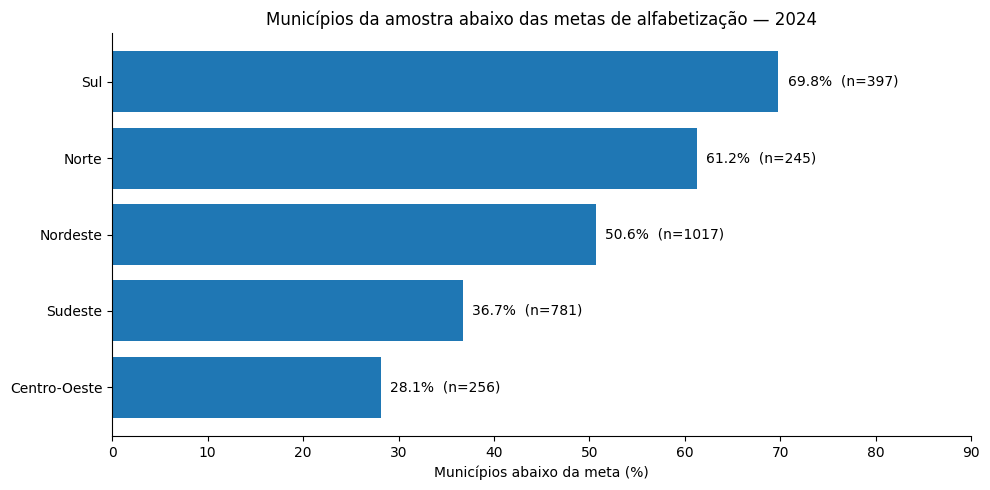

In [33]:
import matplotlib.pyplot as plt
from pathlib import Path

# organizando as regiões para o gráfico
dados_grafico = resumo_regiao.sort_values(
    "pct_abaixo_meta",
    ascending=True,
)

# criando a visualização
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    dados_grafico["regiao"],
    dados_grafico["pct_abaixo_meta"],
)

# adicionando percentuais e quantidades de municípios
for barra, (_, linha) in zip(
    barras,
    dados_grafico.iterrows(),
):
    percentual = barra.get_width()
    municipios = int(linha["municipios"])

    ax.text(
        percentual + 1,
        barra.get_y() + barra.get_height() / 2,
        f"{percentual:.1f}%  (n={municipios})",
        va="center",
    )

# configurando o gráfico
ax.set_xlim(0, 90)
ax.set_xlabel("Municípios abaixo da meta (%)")
ax.set_ylabel("")
ax.set_title(
    "Municípios da amostra abaixo das metas de alfabetização — 2024"
)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

# salvando a imagem na pasta de relatórios
pasta_relatorios = (
    Path("reports/figures")
    if Path("data").exists()
    else Path("../reports/figures")
)

pasta_relatorios.mkdir(parents=True, exist_ok=True)

fig.savefig(
    pasta_relatorios / "metas_alfabetizacao_regioes_2024.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


## 15. Síntese das descobertas e implicações estratégicas

### 15.1. Principais descobertas

A análise integrada dos dados de alfabetização, dos modelos preditivos e das metas municipais permitiu identificar os seguintes resultados:

**1. Limitações da predição individual**

O HistGradientBoosting apresentou ROC-AUC de 0,5906 no teste temporal de 2024 e recall de 14,72% para a classe não alfabetizado.

O desempenho indica que indicadores predominantemente municipais não são suficientes para diferenciar adequadamente alunos alfabetizados e não alfabetizados.

**2. Importância das características educacionais e territoriais**

A Permutation Importance e a análise SHAP destacaram principalmente indicadores associados à presença de bibliotecas, acesso à internet para aprendizagem e características territoriais.

Essas variáveis contribuem para as previsões, mas sua importância não estabelece relações de causa e efeito sobre a alfabetização.

**3. Limitações do risco preditivo municipal**

A correlação de Spearman entre risco médio previsto e proporção observada de não alfabetizados foi de 0,4214, com MAE municipal de 13,34 pontos percentuais.

Na comparação entre os rankings dos maiores riscos previstos e dos maiores déficits em relação às metas, a sobreposição entre os 10% mais críticos foi de apenas 6,87%.

Portanto, as previsões não devem substituir os indicadores educacionais observados na identificação de municípios prioritários.

**4. Desigualdades territoriais no cumprimento das metas**

Entre os 2.696 municípios com metas comparáveis, 1.301 ficaram abaixo da meta de alfabetização em 2024.

Na análise regional, o Sul apresentou a maior proporção de municípios abaixo da meta (69,77%), seguido pelo Norte (61,22%) e Nordeste (50,64%).

O Norte apresentou a menor taxa média municipal de alfabetização (51,18%).

Foram observadas diferenças expressivas entre estados da mesma região, especialmente entre Bahia e Ceará, demonstrando que os indicadores regionais agregados podem ocultar desigualdades internas.

### 15.2. Implicações estratégicas

Os resultados sugerem que o acompanhamento educacional deve considerar múltiplas dimensões:

- **Cumprimento das metas:** identificar municípios com maiores déficits observados.
- **Nível de alfabetização:** distinguir municípios com baixos resultados absolutos daqueles que apenas não alcançaram metas mais elevadas.
- **Participação na avaliação:** contextualizar a representatividade dos indicadores.
- **Características educacionais e territoriais:** investigar desigualdades de infraestrutura e possíveis barreiras locais.

As análises podem apoiar a seleção de territórios para diagnóstico aprofundado, mas não permitem determinar diretamente quais intervenções produzirão melhores resultados.

### 15.3. Limitações e recomendações

O modelo possui capacidade preditiva individual limitada e não deve ser utilizado para decisões automatizadas sobre estudantes.

A análise territorial foi realizada sobre uma amostra de municípios com pelo menos 100 alunos avaliados na rede municipal e metas comparáveis, não representando necessariamente todos os municípios brasileiros.

Como possíveis evoluções, recomenda-se:

- Incorporar variáveis individuais e escolares, quando disponíveis e adequadas ao uso.
- Investigar abordagens de modelagem diretamente municipal.
- Avaliar períodos adicionais para verificar a estabilidade temporal.
- Investigar diferenças regionais e educacionais com métodos apropriados antes de propor intervenções causais.
- Utilizar os indicadores oficiais observados como referência principal para o acompanhamento das metas educacionais.

O principal resultado do projeto é demonstrar tanto as possibilidades quanto as limitações do uso de Machine Learning para análises educacionais, combinando modelagem supervisionada, interpretabilidade e indicadores territoriais.


## 16. Persistência do modelo final

O HistGradientBoosting selecionado foi treinado com todos os registros válidos das redes públicas de 2023 e avaliado temporalmente nos dados de 2024.

Para permitir sua reutilização sem repetir o treinamento, o modelo final será salvo utilizando Joblib.

O artefato contém a pipeline completa do Scikit-learn, incluindo o pré-processamento e o classificador treinado.

Após o salvamento, será verificado se o modelo pode ser carregado novamente e reproduzir as mesmas probabilidades.


In [34]:
from pathlib import Path
import joblib
import numpy as np

# identificando a raiz do projeto
raiz_projeto = (
    Path(".") if Path("data").exists() else Path("..")
)

# criando a pasta para os modelos treinados
pasta_modelos = raiz_projeto / "models"
pasta_modelos.mkdir(parents=True, exist_ok=True)

# definindo o caminho do artefato
caminho_modelo = (
    pasta_modelos / "histgradientboosting_alfabetizacao_2023.joblib"
)

# salvando a pipeline completa
joblib.dump(modelo_final, caminho_modelo)

# carregando o modelo salvo para verificar sua integridade
modelo_carregado = joblib.load(caminho_modelo)

# comparando previsões em uma pequena amostra do treinamento
amostra_verificacao = X_final_treino.iloc[:5]

probabilidades_original = modelo_final.predict_proba(
    amostra_verificacao
)

probabilidades_carregado = modelo_carregado.predict_proba(
    amostra_verificacao
)

np.testing.assert_allclose(
    probabilidades_original,
    probabilidades_carregado,
)

print("Modelo salvo em:", caminho_modelo.resolve())
print("Tipo:", type(modelo_carregado).__name__)
print("Verificação: probabilidades idênticas!")

Modelo salvo em: /home/vitoria/pipeline-alfabetizacao-brasil-fase3/models/histgradientboosting_alfabetizacao_2023.joblib
Tipo: Pipeline
Verificação: probabilidades idênticas!
